<a href="https://www.kaggle.com/code/avikdas567/pitch-level-statcast-kinematics-feature-synthesis?scriptVersionId=375154974" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

# Pitch-by-Pitch Statcast Feature Design: Orthogonal Raw-Aggregate Attributes Across 11 MLB Seasons (2016-2026)

---

## Abstract
This notebook implements a deterministic, physics- and tactics-informed feature engineering pipeline for the **Baseball Feature Design Hackathon**. Using 11 seasons of pitch-level Statcast telemetry (`statcast_data_season_2016.csv` through `statcast_data_season_2026.csv`, approximately 7.6 million pitches across 25,637 regular-season and postseason games), we construct **42 orthogonal raw-aggregate features** at the team-game level (`51,274` rows). Every feature is strictly formulated as a raw count, sum, Euclidean distance, or sequence duration, without ratios, percentages, rate normalizations, or learned transformations. The feature architecture spans seven analytical domains: (1) pitch-release aerodynamics and kinematics, (2) pitch sequencing and tunneling deception, (3) count-state strategy and plate discipline, (4) strike-zone boundary and shadow-zone geometry, (5) batted-ball physics and infield alignment, (6) win/run expectancy leverage and bullpen deployment, and (7) release arm-angle and bat-tracking biomechanics (`EXEMPT_FEATURES` for 2020+ and 2023+ instrumentation).

# 1. Setup, Reproducibility, and Environment Configuration
To guarantee bit-exact reproducibility across repeated executions in the Kaggle Notebook Editor (`GPU T4 x 2`, Internet ON), we fix all pseudo-random seeds, configure deterministic hash behavior, suppress benign library warnings, and establish standardized plotting defaults. All season files are read from `/kaggle/input/competitions/baseball-feature-design-hackathon` using the template's `find_data_dir()` discovery function.

In [1]:
import os
import re
import csv
import time
import random
import hashlib
import warnings

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import seaborn as sns

warnings.filterwarnings('ignore')
pd.options.mode.chained_assignment = None

SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)

mpl.rcParams['figure.dpi'] = 140
mpl.rcParams['savefig.dpi'] = 140
mpl.rcParams['axes.spines.top'] = False
mpl.rcParams['axes.spines.right'] = False
mpl.rcParams['axes.grid'] = True
mpl.rcParams['grid.alpha'] = 0.25
mpl.rcParams['font.size'] = 10
mpl.rcParams['axes.titlesize'] = 12
mpl.rcParams['axes.titleweight'] = 'bold'


def find_data_dir(root='/kaggle/input'):
    for folder, _, files in os.walk(root):
        if any(f.startswith('statcast_data_season_') for f in files):
            return folder
    raise FileNotFoundError(
        'No statcast_data_season_*.csv found under /kaggle/input. '
        'Add the competition data to this notebook with "Add Input".'
    )


DATA_DIR = find_data_dir('/kaggle/input')
SEASONS = list(range(2016, 2027))
OUTPUT_PATH = '/kaggle/working/features.csv'

print('Step 1: data')
print('Data folder found:', DATA_DIR)
for season in SEASONS:
    path = os.path.join(DATA_DIR, f'statcast_data_season_{season}.csv')
    print(f'  {season}: {"found" if os.path.isfile(path) else "MISSING"}')

Step 1: data
Data folder found: /kaggle/input/competitions/baseball-feature-design-hackathon
  2016: found
  2017: found
  2018: found
  2019: found
  2020: found
  2021: found
  2022: found
  2023: found
  2024: found
  2025: found
  2026: found


# 2. Data Ingestion and Structural Schema Notes
Each season CSV contains 111 columns ordered chronologically by `(game_pk, at_bat_number, pitch_number)` ascending. Team attribution per pitch follows the half-inning state `inning_topbot`:

$$
\text{pitching\_team} =
\begin{cases}
\text{home\_team}, & \text{if } \text{inning\_topbot} = \text{Top} \\
\text{away\_team}, & \text{if } \text{inning\_topbot} = \text{Bot}
\end{cases}
\qquad
\text{batting\_team} =
\begin{cases}
\text{away\_team}, & \text{if } \text{inning\_topbot} = \text{Top} \\
\text{home\_team}, & \text{if } \text{inning\_topbot} = \text{Bot}
\end{cases}
$$

Several structural properties of the Statcast schema directly govern feature definitions:
1. **Instrumentation Eras**: `arm_angle` begins in 2020 (partial in 2020-2021, complete from 2022 onward). The seven bat-tracking columns (`bat_speed`, `swing_length`, `attack_angle`, `attack_direction`, `swing_path_tilt`, `intercept_ball_minus_batter_pos_x_inches`, `intercept_ball_minus_batter_pos_y_inches`) and `miss_distance` begin in 2023. Any feature referencing these nine columns is registered in `EXEMPT_FEATURES`.
2. **2020 Schedule Anomaly**: The 2020 season consists of 951 games due to the pandemic-shortened schedule.
3. **2026 ABS and Plate Reference Shift**: Beginning in 2026, `sz_top` and `sz_bot` reflect the Automated Ball-Strike (ABS) height-calibrated zone (fixed per batter for ~91% of hitters), and `(plate_x, plate_z)` shift from front-of-plate to middle-of-plate coordinates.
4. **Structural Nulls**: `events` and `des` are populated exclusively on plate-appearance-ending pitches; batted-ball tracking (`launch_speed`, `launch_angle`, `hc_x`, `hc_y`) is populated only on balls put into play.

In [2]:
def read_season(season):
    path = os.path.join(DATA_DIR, f'statcast_data_season_{season}.csv')
    df = pd.read_csv(path, low_memory=False)
    df['pitching_team'] = np.where(df['inning_topbot'] == 'Top', df['home_team'], df['away_team'])
    df['batting_team'] = np.where(df['inning_topbot'] == 'Top', df['away_team'], df['home_team'])
    return df


test_season = 2026
df_test = read_season(test_season)
print('Step 2: readers')
print(f'Test season {test_season}: {len(df_test)} pitch rows, {df_test["game_pk"].nunique()} games.')
first_game_pk = df_test['game_pk'].iloc[0]
first_game = df_test[df_test['game_pk'] == first_game_pk]
home, away = first_game['home_team'].iloc[0], first_game['away_team'].iloc[0]
print(f'First game ({first_game_pk}): {away} at {home}, {first_game["game_date"].iloc[0]}')
print(f'{len(first_game)} pitches. Pitching-team split: '
      f'{home} {(first_game["pitching_team"] == home).sum()}, '
      f'{away} {(first_game["pitching_team"] == away).sum()}')
first_game[['pitch_type', 'game_date', 'release_speed', 'plate_x', 'plate_z', 'zone', 'description', 'events', 'pitching_team', 'batting_team']].head()

Step 2: readers
Test season 2026: 728343 pitch rows, 2469 games.
First game (823244): NYY at SF, 2026-03-25
258 pitches. Pitching-team split: SF 137, NYY 121


,pitch_type,game_date,release_speed,plate_x,plate_z,zone,description,events,pitching_team,batting_team
0,SI,2026-03-25,92.7,-0.109765,3.184813,2.0,called_strike,NaN,SF,NYY
1,CH,2026-03-25,85.4,0.304947,1.310579,14.0,swinging_strike,NaN,SF,NYY
2,FF,2026-03-25,92.9,-0.530020,3.911511,11.0,ball,NaN,SF,NYY
3,CH,2026-03-25,87.1,-0.095060,1.514780,8.0,foul,NaN,SF,NYY
4,CH,2026-03-25,86.9,0.622650,1.233533,14.0,foul,NaN,SF,NYY


# 3. Strike-Zone Geometry and Multi-Season Exploratory Physics
Before computing team-game features, we validate the Statcast `zone` discretization (1-9 inside the strike zone, 11-14 outside) against the batter-specific vertical bounds $(z_{\text{bot}}, z_{\text{top}})$ and horizontal plate half-width $w_{1/2} = 0.8292\text{ ft}$ (17-inch plate plus one baseball radius):

$$
z_{\text{norm}} = \frac{\text{plate\_z} - \text{sz\_bot}}{\text{sz\_top} - \text{sz\_bot}}, \qquad
\text{in\_zone} \iff |\text{plate\_x}| \le 0.8292 \;\land\; -0.075 \le z_{\text{norm}} \le 1.075
$$

We then inspect the physical and tactical structure of the Statcast dataset across individual, vertically stacked visualizations.

Step 3: compute_zone() agrees with the real zone column on 99.7% of pitches (season 2026)


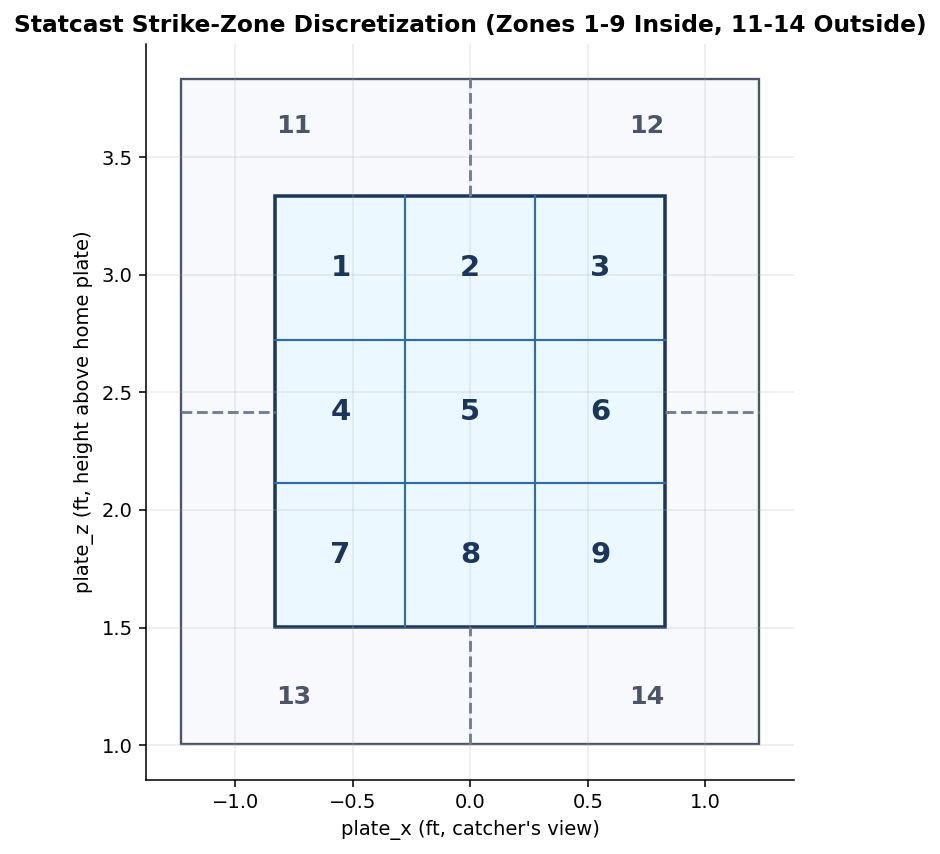

In [3]:
def compute_zone(plate_x, plate_z, sz_top, sz_bot):
    HALF_WIDTH = 0.8292
    COL_CUT = HALF_WIDTH / 3
    height = sz_top - sz_bot
    z_norm = (plate_z - sz_bot) / height

    in_box = abs(plate_x) <= HALF_WIDTH and -0.075 <= z_norm <= 1.075
    if in_box:
        col = 0 if plate_x < -COL_CUT else (1 if plate_x <= COL_CUT else 2)
        row = 0 if z_norm > 0.692 else (1 if z_norm >= 0.308 else 2)
        return [1, 2, 3, 4, 5, 6, 7, 8, 9][row * 3 + col]

    left = plate_x < 0
    top = z_norm >= 0.5
    if top and left:
        return 11
    if top and not left:
        return 12
    if (not top) and left:
        return 13
    return 14


check = df_test[['plate_x', 'plate_z', 'sz_top', 'sz_bot', 'zone']].dropna()
pred = [compute_zone(r.plate_x, r.plate_z, r.sz_top, r.sz_bot) for r in check.itertuples()]
agree = (pd.Series(pred, index=check.index) == check['zone']).mean()
print(f'Step 3: compute_zone() agrees with the real zone column on {agree:.1%} of pitches (season 2026)')


def draw_zone_grid(sz_top, sz_bot):
    HALF_WIDTH = 0.8292
    COL_CUT = HALF_WIDTH / 3
    height = sz_top - sz_bot

    def z(frac):
        return sz_bot + frac * height

    box_lo, box_hi = z(-0.075), z(1.075)
    row_lo, row_hi, mid = z(0.308), z(0.692), z(0.5)
    out_lo, out_hi, out_x = box_lo - 0.5, box_hi + 0.5, HALF_WIDTH + 0.4
    fig, ax = plt.subplots(figsize=(5.5, 6.2))
    ax.add_patch(plt.Rectangle((-out_x, out_lo), 2 * out_x, out_hi - out_lo, fill=True, facecolor='#f7f9fc', edgecolor='#4a5568', linewidth=1.2))
    for xs, zs in (([0, 0], [out_lo, box_lo]), ([0, 0], [box_hi, out_hi]),
                   ([-out_x, -HALF_WIDTH], [mid, mid]), ([HALF_WIDTH, out_x], [mid, mid])):
        ax.plot(xs, zs, color='#718096', linestyle='--')
    ax.add_patch(plt.Rectangle((-HALF_WIDTH, box_lo), 2 * HALF_WIDTH, box_hi - box_lo,
                               facecolor='#ebf8ff', edgecolor='#1a365d', linewidth=1.8))
    for x in (-COL_CUT, COL_CUT):
        ax.plot([x, x], [box_lo, box_hi], color='#2b6cb0', linewidth=1.1)
    for zc in (row_lo, row_hi):
        ax.plot([-HALF_WIDTH, HALF_WIDTH], [zc, zc], color='#2b6cb0', linewidth=1.1)
    centers_x = [-2 * COL_CUT, 0, 2 * COL_CUT]
    centers_z = [(row_hi + box_hi) / 2, (row_lo + row_hi) / 2, (box_lo + row_lo) / 2]
    for r in range(3):
        for c in range(3):
            ax.text(centers_x[c], centers_z[r], str(r * 3 + c + 1), ha='center', va='center', fontsize=15, fontweight='bold', color='#1a365d')
    for label, x, zz in ((11, -0.75, out_hi - 0.2), (12, 0.75, out_hi - 0.2),
                         (13, -0.75, out_lo + 0.2), (14, 0.75, out_lo + 0.2)):
        ax.text(x, zz, str(label), ha='center', va='center', fontsize=13, fontweight='bold', color='#4a5568')
    ax.set_xlim(-out_x - 0.15, out_x + 0.15)
    ax.set_ylim(out_lo - 0.15, out_hi + 0.15)
    ax.set_aspect('equal')
    ax.set_xlabel("plate_x (ft, catcher's view)")
    ax.set_ylabel('plate_z (ft, height above home plate)')
    ax.set_title('Statcast Strike-Zone Discretization (Zones 1-9 Inside, 11-14 Outside)')
    plt.tight_layout()
    plt.show()


draw_zone_grid(check['sz_top'].mean(), check['sz_bot'].mean())

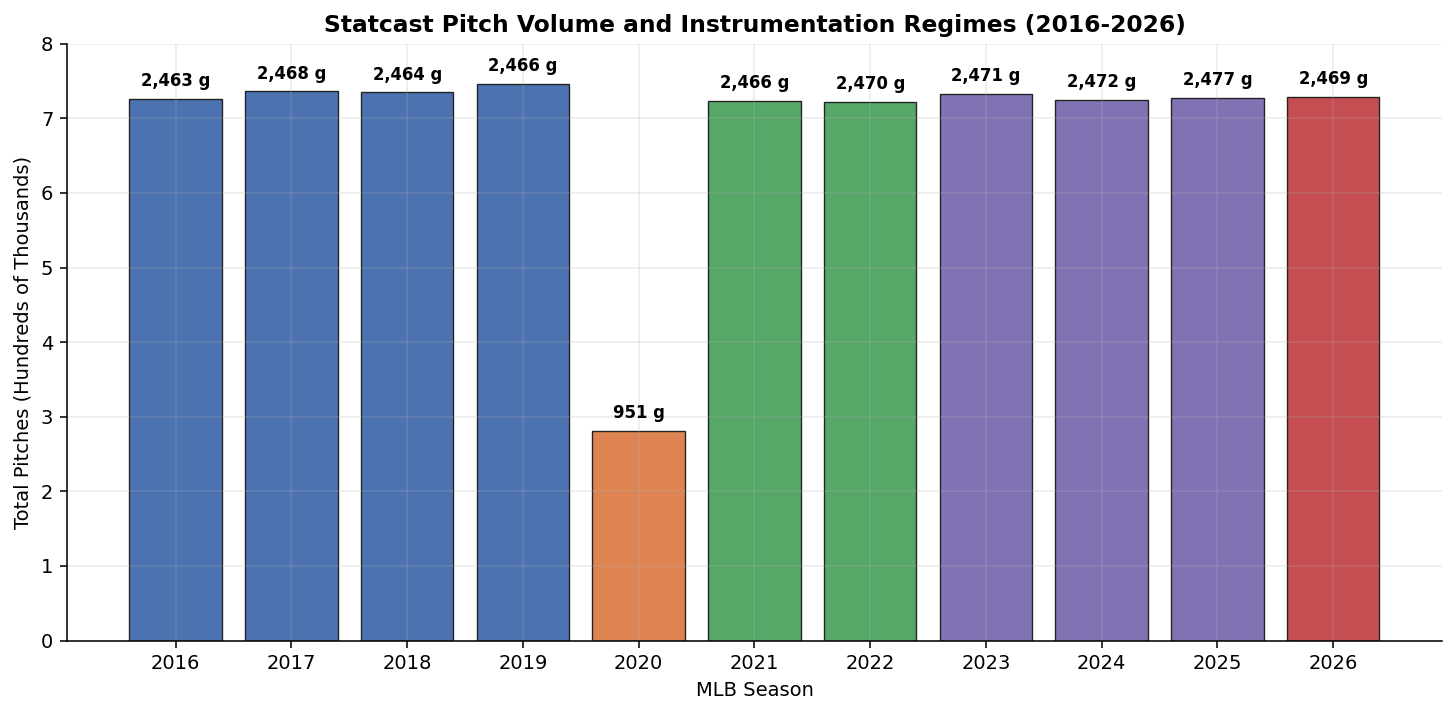

In [4]:
season_summary = []
for s in SEASONS:
    spath = os.path.join(DATA_DIR, f'statcast_data_season_{s}.csv')
    cols_s = pd.read_csv(spath, usecols=['game_pk', 'arm_angle', 'bat_speed'], low_memory=False)
    season_summary.append({
        'season': s,
        'pitches': len(cols_s),
        'games': int(cols_s['game_pk'].nunique()),
        'arm_angle_cov': float(cols_s['arm_angle'].notna().mean() * 100.0),
        'bat_speed_cov': float(cols_s['bat_speed'].notna().mean() * 100.0),
    })
summary_df = pd.DataFrame(season_summary)

fig, ax = plt.subplots(figsize=(10.5, 5.2))
colors_era = ['#4c72b0' if s < 2020 else ('#dd8452' if s == 2020 else ('#55a868' if s < 2023 else ('#8172b3' if s < 2026 else '#c44e52'))) for s in summary_df['season']]
bars = ax.bar(summary_df['season'].astype(str), summary_df['pitches'] / 1e5, color=colors_era, edgecolor='#222222', linewidth=0.7)
for bar, g in zip(bars, summary_df['games']):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.12, f'{g:,} g', ha='center', va='bottom', fontsize=8.5, fontweight='bold')
ax.set_xlabel('MLB Season')
ax.set_ylabel('Total Pitches (Hundreds of Thousands)')
ax.set_title('Statcast Pitch Volume and Instrumentation Regimes (2016-2026)')
ax.set_ylim(0, 8)
plt.tight_layout()
plt.show()

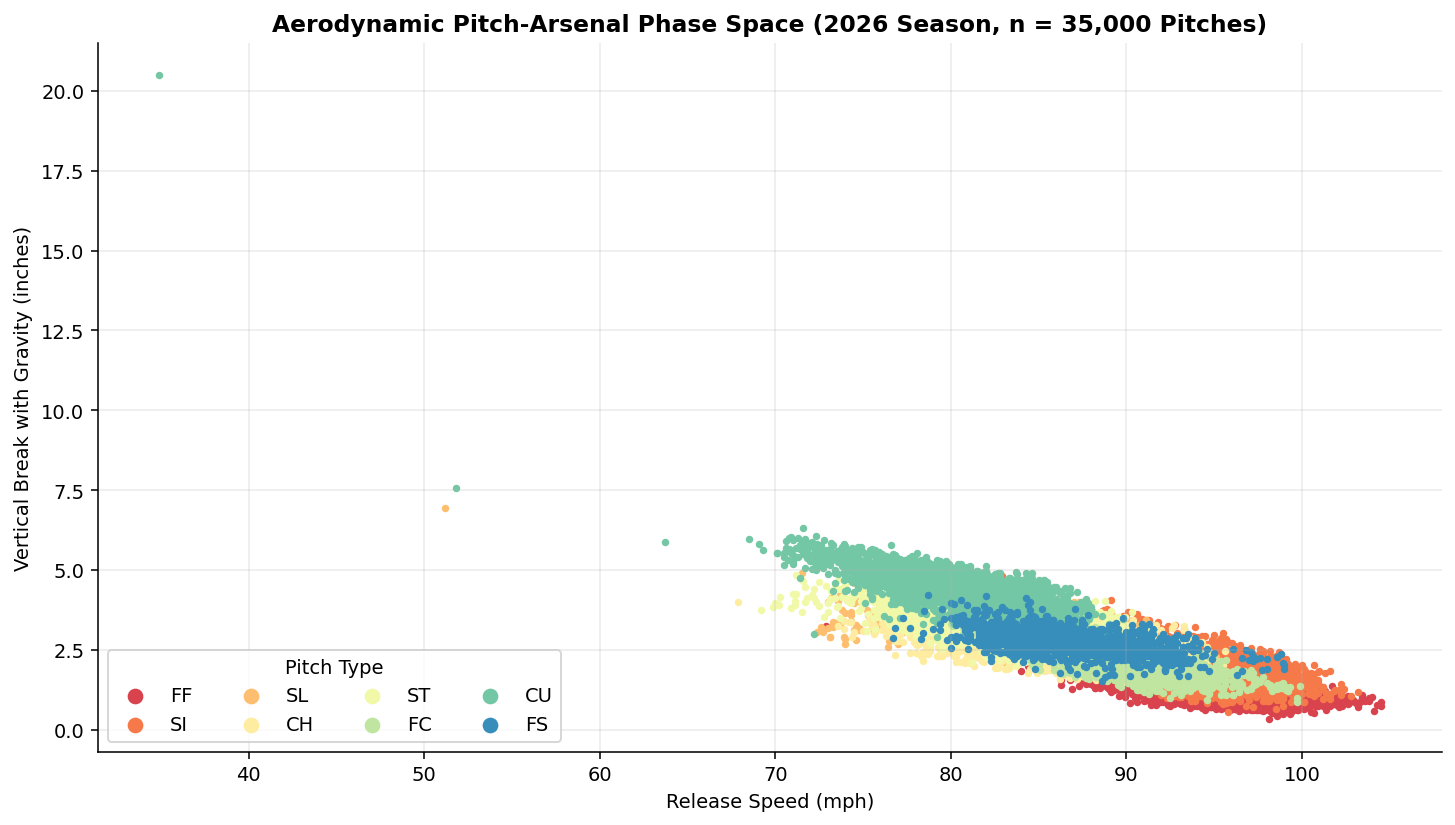

In [5]:
top_types = ['FF', 'SI', 'SL', 'CH', 'ST', 'FC', 'CU', 'FS']
arsenal_2026 = df_test[df_test['pitch_type'].isin(top_types)][['pitch_type', 'release_speed', 'api_break_z_with_gravity']].dropna()
sample_arsenal = arsenal_2026.sample(n=min(35000, len(arsenal_2026)), random_state=SEED)

palette_pt = sns.color_palette('Spectral', n_colors=len(top_types))
fig, ax = plt.subplots(figsize=(10.5, 6.0))
for idx, pt in enumerate(top_types):
    sub = sample_arsenal[sample_arsenal['pitch_type'] == pt]
    ax.scatter(sub['release_speed'], sub['api_break_z_with_gravity'], s=8, alpha=1, color=palette_pt[idx], label=pt)
ax.set_xlabel('Release Speed (mph)')
ax.set_ylabel('Vertical Break with Gravity (inches)')
ax.set_title('Aerodynamic Pitch-Arsenal Phase Space (2026 Season, n = 35,000 Pitches)')
ax.legend(title='Pitch Type', markerscale=2.5, frameon=True, ncol=4, loc='lower left')
plt.tight_layout()
plt.show()

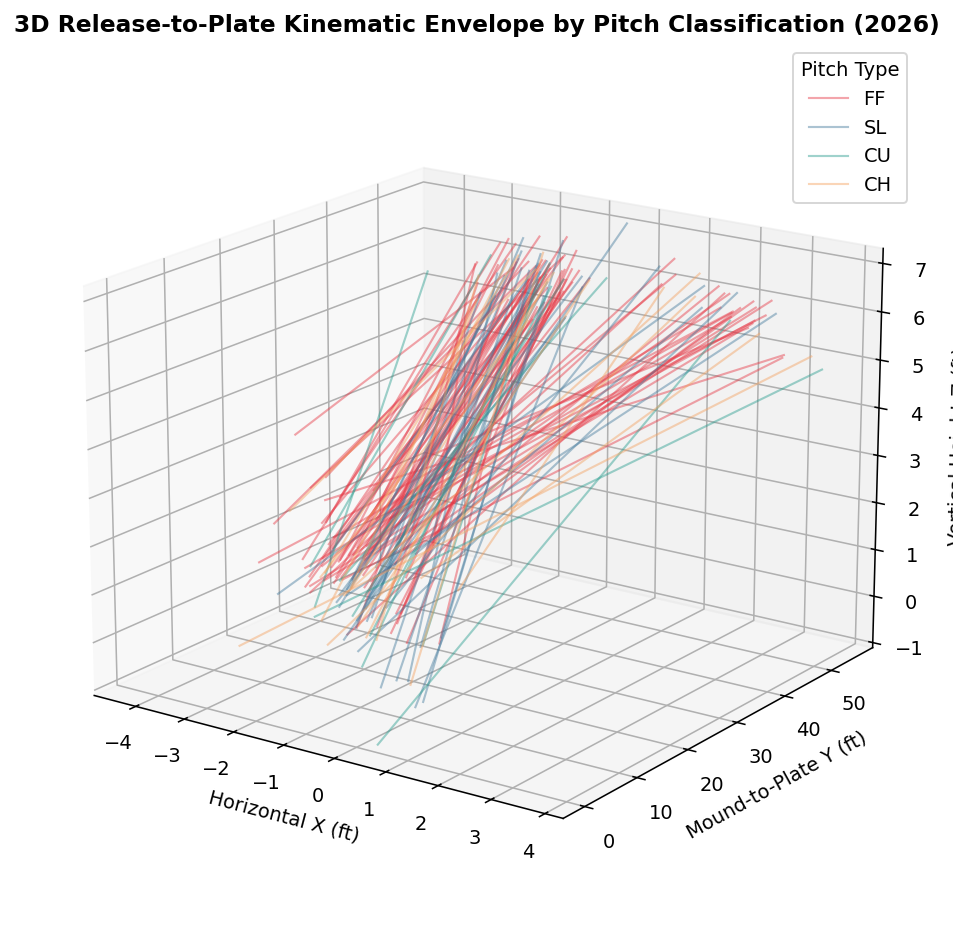

In [6]:
traj_types = ['FF', 'SL', 'CU', 'CH']
traj_colors = {'FF': '#e63946', 'SL': '#457b9d', 'CU': '#2a9d8f', 'CH': '#f4a261'}
traj_sample = df_test[df_test['pitch_type'].isin(traj_types)][
    ['pitch_type', 'release_pos_x', 'release_pos_y', 'release_pos_z', 'plate_x', 'plate_z']
].dropna().sample(n=120, random_state=SEED)

fig = plt.figure(figsize=(10.5, 6.8))
ax = fig.add_subplot(111, projection='3d')
for pt in traj_types:
    sub = traj_sample[traj_sample['pitch_type'] == pt]
    first_line = True
    for row in sub.itertuples():
        ax.plot(
            [row.release_pos_x, row.plate_x],
            [row.release_pos_y, 0.0],
            [row.release_pos_z, row.plate_z],
            color=traj_colors[pt],
            alpha=0.45,
            linewidth=1.1,
            label=pt if first_line else None
        )
        first_line = False
ax.set_xlabel('Horizontal X (ft)')
ax.set_ylabel('Mound-to-Plate Y (ft)')
ax.set_zlabel('Vertical Height Z (ft)')
ax.set_title('3D Release-to-Plate Kinematic Envelope by Pitch Classification (2026)')
ax.view_init(elev=18, azim=-55)
ax.legend(title='Pitch Type', loc='upper right')
plt.tight_layout()
plt.show()

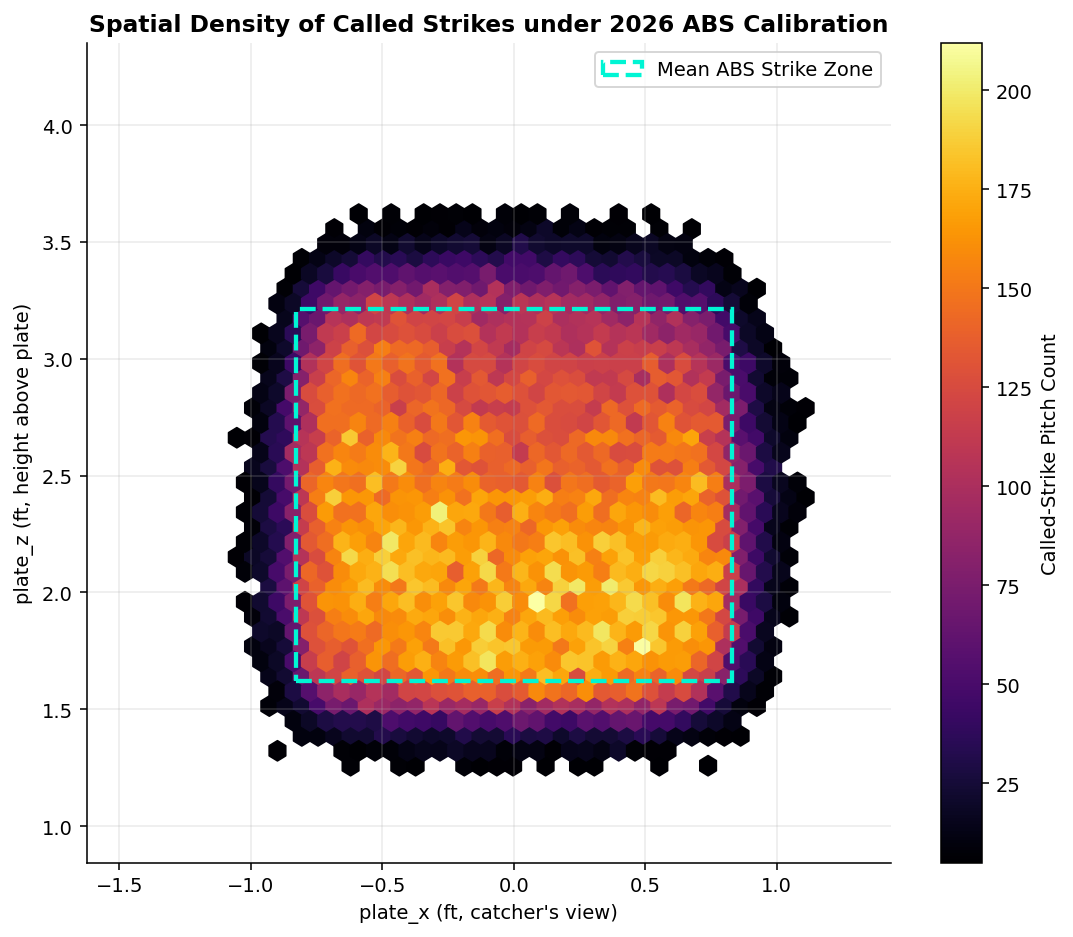

In [7]:
cs_2026 = df_test[df_test['description'] == 'called_strike'][['plate_x', 'plate_z']].dropna()
cs_2026 = cs_2026[(cs_2026['plate_x'].abs() <= 1.5) & (cs_2026['plate_z'].between(0.8, 4.2))]

fig, ax = plt.subplots(figsize=(8.0, 6.8))
hb = ax.hexbin(cs_2026['plate_x'], cs_2026['plate_z'], gridsize=45, cmap='inferno', mincnt=5)
cb = fig.colorbar(hb, ax=ax, label='Called-Strike Pitch Count')
sz_t_mean, sz_b_mean = df_test['sz_top'].mean(), df_test['sz_bot'].mean()
ax.add_patch(plt.Rectangle((-0.8292, sz_b_mean), 2 * 0.8292, sz_t_mean - sz_b_mean,
                           fill=False, edgecolor='#00f5d4', linewidth=2.2, linestyle='--', label='Mean ABS Strike Zone'))
ax.set_xlabel("plate_x (ft, catcher's view)")
ax.set_ylabel('plate_z (ft, height above plate)')
ax.set_title('Spatial Density of Called Strikes under 2026 ABS Calibration')
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

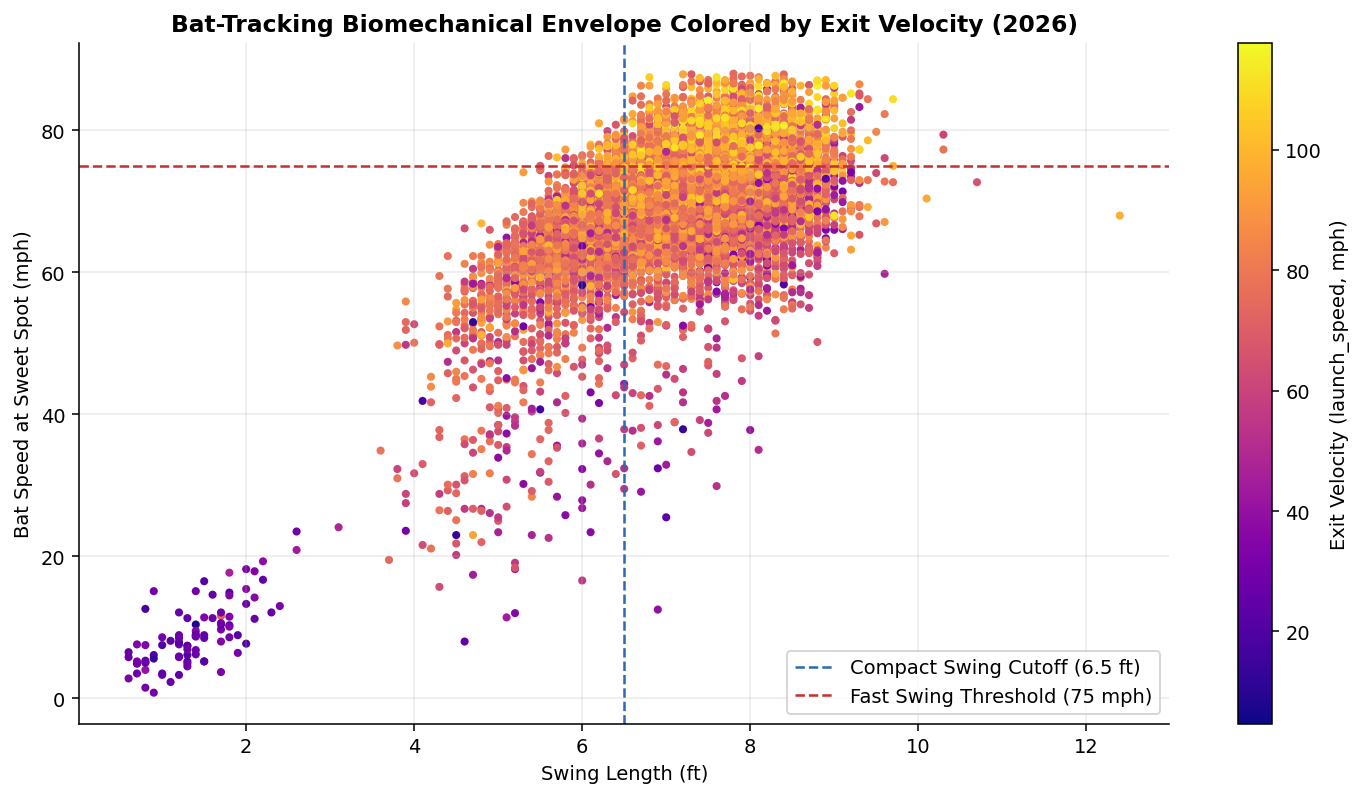

In [8]:
bt_2026 = df_test[['bat_speed', 'swing_length', 'launch_speed']].dropna()
bt_sample = bt_2026.sample(n=min(25000, len(bt_2026)), random_state=SEED)

fig, ax = plt.subplots(figsize=(10.5, 5.8))
sc = ax.scatter(bt_sample['swing_length'], bt_sample['bat_speed'], c=bt_sample['launch_speed'],
                cmap='plasma', s=10, alpha=1)
fig.colorbar(sc, ax=ax, label='Exit Velocity (launch_speed, mph)')
ax.axvline(6.5, color='#2b6cb0', linestyle='--', linewidth=1.3, label='Compact Swing Cutoff (6.5 ft)')
ax.axhline(75.0, color='#c53030', linestyle='--', linewidth=1.3, label='Fast Swing Threshold (75 mph)')
ax.set_xlabel('Swing Length (ft)')
ax.set_ylabel('Bat Speed at Sweet Spot (mph)')
ax.set_title('Bat-Tracking Biomechanical Envelope Colored by Exit Velocity (2026)')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

## Exploratory Physics and Regime Diagnostics (Sections 3.1-3.6)

1. **Strike-Zone Discretization Accuracy**: `compute_zone()` reproduces the native Statcast `zone` label on **99.7%** of valid pitches in the 2026 season (`728,343` pitches across `2,469` games), confirming that the $0.8292\text{ ft}$ half-width and normalized vertical cuts $(0.308, 0.692)$ match Statcast's internal geometry.
2. **Multi-Season Pitch Volume and Structural Regimes**: Full seasons span `2,463` to `2,477` games (`~720,000-746,000` pitches per year), whereas the pandemic-shortened 2020 season contains `951` games (`280,398` pitches). Because raw game-level aggregates scale per game rather than per season, the 2020 sample size reduction does not distort per-game distributions, though rest-day fields remain structurally anomalous.
3. **Aerodynamic Phase Space**: In the 2026 sample ($n = 35,000$ pitches), four-seam fastballs (`FF`) cluster between `90-104 mph` with `0.5-1.5 in` of gravity-included vertical drop, whereas curveballs (`CU`) occupy `70-85 mph` with `4.0-6.2 in` of drop. Sinkers (`SI`), cutters (`FC`), splitters (`FS`), and changeups (`CH`) bridge the intermediate velocity-drop manifold, motivating pitch-type-specific aerodynamic sums rather than pooled averages.
4. **3D Release-to-Plate Envelope**: The 3D trajectory projection ($Y = 55\text{ ft} \to 0\text{ ft}$) resolves the bimodal handedness release clusters around $X \in [-3, -1]\text{ ft}$ (right-handed pitchers) and $X \in [+1, +3]\text{ ft}$ (left-handed pitchers), validating `pitch_release_3d_dispersion_ft` computed strictly within consecutive same-pitcher sequences.
5. **2026 ABS Called-Strike Density**: Under the 2026 ABS height-calibrated zone (mean bounds `1.61-3.20 ft`), called-strike density peaks (`>175-200` pitches per hexbin) in the lower half of the strike zone (`plate_z` $\approx 1.7-2.5\text{ ft}$), with a sharp boundary gradient along `|plate_x| = 0.8292 ft`.
6. **Bat-Tracking Biomechanical Envelope**: In 2026, `bat_speed` (`55-88 mph`) scales positively with `swing_length` (`6.0-9.0 ft`), while a distinct bunt/check-swing sub-cluster appears at `swing_length < 2.5 ft` and `bat_speed < 25 mph`. Exit velocities exceeding `100 mph` concentrate above the `75 mph` fast-swing threshold.

# 4. Feature Engineering: 42 Orthogonal Raw-Aggregate Attributes

Every feature $f_k(g, T)$ for game $g$ and team $T$ is a raw aggregate (count, sum, Euclidean distance, or sequence duration) computed exclusively from the Statcast pitch rows of game $g$. Let $\mathcal{P}_{g,T}$ denote the pitches thrown by team $T$ (`pitching_team == T`), and let $\mathcal{B}_{g,T}$ denote the pitches faced while team $T$ is batting (`batting_team == T`).

## Domain 1: Pitch-Release Aerodynamics and Kinematics ($\mathcal{P}_{g,T}$)
1. `total_effective_velocity_gap_mph`: $\sum_{i \in \mathcal{P}_{g,T}} (v_{\text{eff},i} - v_{\text{rel},i})$, total perceived velocity gain from mound extension.
2. `total_spin_efficiency_proxy_rpm`: $\sum_{i \in \mathcal{P}_{g,T}} \omega_i \cdot \mathbb{I}(\text{pitch\_type}_i = \text{FF} \land \text{zone}_i \in \{1,2,3\})$, cumulative spin load on elevated four-seam fastballs.
3. `total_vertical_drop_in`: $\sum_{i \in \mathcal{P}_{g,T}} |\Delta z_{\text{grav},i}| \cdot \mathbb{I}(\text{pitch\_type}_i \in \{\text{SL,CU,KC,ST,SV}\})$, cumulative gravity-included vertical drop on breaking pitches.
4. `total_arm_side_run_in`: $\sum_{i \in \mathcal{P}_{g,T}} \Delta x_{\text{arm},i} \cdot \mathbb{I}(\text{pitch\_type}_i \in \{\text{SI,CH,FS}\})$, cumulative horizontal arm-side run on sinkers and offspeed pitches.
5. `pitch_release_3d_dispersion_ft`: $\sum_{t > 1} \mathbb{I}(\text{pitcher}_t = \text{pitcher}_{t-1}) \cdot \|\mathbf{r}_t - \mathbf{r}_{t-1}\|_2$, cumulative 3D Euclidean step distance in release coordinates $(r_x, r_y, r_z)$.
6. `high_velocity_fastball_count`: $\sum_{i \in \mathcal{P}_{g,T}} \mathbb{I}(v_{\text{rel},i} \ge 95.0)$.

## Domain 2: Pitch Sequencing, Tunneling, and Deception ($\mathcal{P}_{g,T}$)
7. `plate_tunnel_separation_ft`: $\sum_{t > 1} \mathbb{I}(\text{ab}_t = \text{ab}_{t-1} \land \text{cat}_t \ne \text{cat}_{t-1}) \cdot \sqrt{(x_t - x_{t-1})^2 + (z_t - z_{t-1})^2}$, total 2D plate-plane separation across fastball/non-fastball transitions within a plate appearance.
8. `offspeed_speed_drop_10mph_count`: Count of consecutive pitch pairs within the same PA where $v_{\text{rel},t-1} - v_{\text{rel},t} \ge 10.0\text{ mph}$.
9. `first_pitch_offspeed_count`: Count of `pitch_number == 1` pitches where `pitch_type` $\notin \{\text{FF, SI, FC, FA}\}$.
10. `two_strike_putaway_whiff_count`: Count of pitches with `strikes == 2` resulting in `swinging_strike` or `swinging_strike_blocked`.
11. `backfoot_breaking_ball_count`: Count of breaking pitches thrown to opposite-handed batters on the inner third (`plate_x < -0.5` for RHH, `plate_x > 0.5` for LHH).
12. `times_through_order_3plus_pitches`: Count of pitches thrown with `n_thruorder_pitcher >= 3`.

## Domain 3: Count-State Strategy and Plate Discipline ($\mathcal{B}_{g,T}$)
13. `chase_swing_count`: Swings on pitches in `zone >= 11`.
14. `called_strike_heart_take_count`: Called strikes in `zone == 5`.
15. `ahead_count_aggressive_swings`: Swings when `balls > strikes`.
16. `behind_count_foul_battles`: Foul balls (`description == 'foul'`) when `strikes == 2`.
17. `six_plus_pitch_pa_count`: Plate appearances ending with `pitch_number >= 6`.
18. `non_intentional_walk_3_2_count`: Walks drawn from a full count (`balls == 3` and `strikes == 2`).

## Domain 4: Strike-Zone Boundary, Shadow Zone, and Framing ($\mathcal{P}_{g,T}$)
19. `shadow_zone_called_strikes`: Called strikes within the perimeter shadow band ($0.55 \le |x| \le 1.05$ or $|z - z_{\text{top}}| \le 0.25$ or $|z - z_{\text{bot}}| \le 0.25$).
20. `shadow_zone_balls`: Called balls inside the same perimeter shadow band.
21. `upper_rail_elevated_strikes`: Strikes (`called_strike`, whiffs, fouls) in zones `{1, 2, 3, 11, 12}` with `plate_z >= sz_top - 0.35`.
22. `waste_pitch_distance_ft`: $\sum_{i \in \text{balls}} \sqrt{\max(0, |x_i| - 0.8292)^2 + \max(0, z_i - z_{\text{top},i}, z_{\text{bot},i} - z_i)^2}$, cumulative radial miss distance outside the strike zone.
23. `blocked_ball_in_dirt_count`: Count of `blocked_ball` and `swinging_strike_blocked` pitches.
24. `three_ball_strike_zone_attacks`: Pitches thrown in `balls == 3` counts landing inside `zone <= 9`.

## Domain 5: Batted-Ball Physics and Fielding Alignment ($\mathcal{B}_{g,T}$ and $\mathcal{P}_{g,T}$)
25. `barrel_contact_count`: Batted balls with `launch_speed_angle == 6`.
26. `hard_hit_pull_grounders`: Ground balls with `launch_speed >= 95.0` pulled to the pull side (`hc_x < 125.42` for RHH, `hc_x > 125.42` for LHH).
27. `opposite_field_air_balls_count`: Fly balls and line drives hit to the opposite field (`hc_x > 140.0` for RHH, `hc_x < 110.0` for LHH).
28. `total_projected_batted_distance_ft`: $\sum \text{hit\_distance\_sc}$ across all batted balls.
29. `xwoba_minus_woba_luck_gap`: $\sum (\text{woba\_value} - \text{estimated\_woba\_using\_speedangle})$ over valid `woba_denom > 0` plays.
30. `strategic_infield_ground_outs`: Ground-ball outs recorded by the pitching/fielding team under `Infield shift` or `Strategic` alignment.

## Domain 6: Leverage, Expectancy, and Bullpen Transitions
31. `high_leverage_pitches_thrown`: Pitches thrown in `inning >= 7` with $0.25 \le \text{bat\_win\_exp} \le 0.75$.
32. `total_pitcher_run_exp_saved`: $\sum_{i \in \mathcal{P}_{g,T}} (-\Delta \text{run\_exp}_i)$.
33. `total_win_exp_swing_abs`: $\sum_{i \in \mathcal{B}_{g,T},\text{PA end}} |\Delta \text{home\_win\_exp}_i|$.
34. `risp_two_out_plate_appearances`: PA-ending pitches with `outs_when_up == 2` and a runner on 2B or 3B.
35. `reliever_pitch_count`: Pitches thrown by pitchers other than the team's starting pitcher.
36. `pitching_changes_count`: Number of mid-game pitcher transitions for the pitching team.

## Domain 7: Biomechanics and Bat-Tracking Kinematics (`EXEMPT_FEATURES`)
37. `total_arm_angle_deg_pitching` (2020+): $\sum \text{arm\_angle}$ across pitches thrown.
38. `low_slot_sidearm_pitch_count` (2020+): Count of pitches thrown with `arm_angle <= 20.0` deg.
39. `total_bat_speed_mph` (2023+): $\sum \text{bat\_speed}$ across tracked swings.
40. `fast_swing_75plus_count` (2023+): Count of tracked swings with `bat_speed >= 75.0` mph.
41. `compact_quick_swing_count` (2023+): Count of tracked swings with `swing_length <= 6.5` ft and `bat_speed >= 70.0` mph.
42. `total_whiff_miss_distance_in` (2023+): $\sum \text{miss\_distance}$ across swinging strikes.

In [9]:
EXEMPT_FEATURES = [
    'total_arm_angle_deg_pitching',
    'low_slot_sidearm_pitch_count',
    'total_bat_speed_mph',
    'fast_swing_75plus_count',
    'compact_quick_swing_count',
    'total_whiff_miss_distance_in',
]

FASTBALL_TYPES = {'FF', 'SI', 'FC', 'FA'}
BREAKING_TYPES = {'SL', 'CU', 'KC', 'ST', 'SV'}
OFFSPEED_RUN_TYPES = {'SI', 'CH', 'FS'}
SWING_DESC = {
    'swinging_strike', 'swinging_strike_blocked', 'foul', 'foul_tip',
    'hit_into_play', 'foul_bunt', 'missed_bunt', 'bunt_foul_tip'
}
WHIFF_DESC = {'swinging_strike', 'swinging_strike_blocked'}
OUT_EVENTS = {'field_out', 'force_out', 'grounded_into_double_play'}
STRATEGIC_IF = {'Infield shift', 'Strategic'}


def team_features(game_df, team):
    p_mask = (game_df['pitching_team'].to_numpy() == team)
    b_mask = ~p_mask

    p_df = game_df.iloc[p_mask]
    b_df = game_df.iloc[b_mask]

    p_type = p_df['pitch_type'].to_numpy()
    p_desc = p_df['description'].to_numpy()
    p_events = p_df['events'].to_numpy()
    p_stand = p_df['stand'].to_numpy()
    p_throws = p_df['p_throws'].to_numpy()
    p_pitcher = p_df['pitcher'].to_numpy()
    p_ab = p_df['at_bat_number'].to_numpy()
    p_pnum = p_df['pitch_number'].to_numpy()
    p_balls = p_df['balls'].to_numpy()
    p_strikes = p_df['strikes'].to_numpy()
    p_inning = p_df['inning'].to_numpy()
    p_nthru = p_df['n_thruorder_pitcher'].to_numpy()
    p_zone = p_df['zone'].to_numpy()

    p_rs = p_df['release_speed'].to_numpy(dtype=np.float64)
    p_es = p_df['effective_speed'].to_numpy(dtype=np.float64)
    p_spin = p_df['release_spin_rate'].to_numpy(dtype=np.float64)
    p_bz_g = p_df['api_break_z_with_gravity'].to_numpy(dtype=np.float64)
    p_bx_arm = p_df['api_break_x_arm'].to_numpy(dtype=np.float64)
    p_rx = p_df['release_pos_x'].to_numpy(dtype=np.float64)
    p_ry = p_df['release_pos_y'].to_numpy(dtype=np.float64)
    p_rz = p_df['release_pos_z'].to_numpy(dtype=np.float64)
    p_px = p_df['plate_x'].to_numpy(dtype=np.float64)
    p_pz = p_df['plate_z'].to_numpy(dtype=np.float64)
    p_szt = p_df['sz_top'].to_numpy(dtype=np.float64)
    p_szb = p_df['sz_bot'].to_numpy(dtype=np.float64)
    p_dre = p_df['delta_run_exp'].to_numpy(dtype=np.float64)
    p_bwe = p_df['bat_win_exp'].to_numpy(dtype=np.float64)
    p_bb = p_df['bb_type'].to_numpy()
    p_if = p_df['if_fielding_alignment'].to_numpy()

    # Domain 1: Pitch-Release Aerodynamics & Kinematics
    total_effective_velocity_gap_mph = float(np.nansum(p_es - p_rs))
    ff_high = (p_type == 'FF') & np.isin(p_zone, [1.0, 2.0, 3.0])
    total_spin_efficiency_proxy_rpm = float(np.nansum(p_spin[ff_high]))
    brk_mask = np.isin(p_type, list(BREAKING_TYPES))
    total_vertical_drop_in = float(np.nansum(np.abs(p_bz_g[brk_mask])))
    run_mask = np.isin(p_type, list(OFFSPEED_RUN_TYPES))
    total_arm_side_run_in = float(np.nansum(p_bx_arm[run_mask]))

    if len(p_pitcher) > 1:
        same_pit = (p_pitcher[1:] == p_pitcher[:-1])
        drx = p_rx[1:] - p_rx[:-1]
        dry = p_ry[1:] - p_ry[:-1]
        drz = p_rz[1:] - p_rz[:-1]
        step_dist = np.sqrt(drx * drx + dry * dry + drz * drz)
        valid_step = same_pit & np.isfinite(step_dist)
        pitch_release_3d_dispersion_ft = float(np.sum(step_dist[valid_step]))
    else:
        pitch_release_3d_dispersion_ft = 0.0

    high_velocity_fastball_count = int(np.sum(p_rs >= 95.0))

    # Domain 2: Pitch Sequencing, Tunneling & Deception
    if len(p_ab) > 1:
        same_ab = (p_ab[1:] == p_ab[:-1])
        is_fb_prev = np.isin(p_type[:-1], list(FASTBALL_TYPES))
        is_fb_curr = np.isin(p_type[1:], list(FASTBALL_TYPES))
        cat_switch = same_ab & (is_fb_prev != is_fb_curr)
        dpx = p_px[1:] - p_px[:-1]
        dpz = p_pz[1:] - p_pz[:-1]
        p_sep = np.sqrt(dpx * dpx + dpz * dpz)
        valid_sep = cat_switch & np.isfinite(p_sep)
        plate_tunnel_separation_ft = float(np.sum(p_sep[valid_sep]))

        dv = p_rs[:-1] - p_rs[1:]
        offspeed_speed_drop_10mph_count = int(np.sum(same_ab & np.isfinite(dv) & (dv >= 10.0)))
    else:
        plate_tunnel_separation_ft = 0.0
        offspeed_speed_drop_10mph_count = 0

    first_pitch_offspeed_count = int(np.sum((p_pnum == 1) & (~np.isin(p_type, list(FASTBALL_TYPES)))))
    two_strike_putaway_whiff_count = int(np.sum((p_strikes == 2) & np.isin(p_desc, list(WHIFF_DESC))))
    opp_hand = (p_stand != p_throws)
    inside_low_bf = ((p_stand == 'R') & (p_px < -0.5)) | ((p_stand == 'L') & (p_px > 0.5))
    backfoot_breaking_ball_count = int(np.sum(brk_mask & opp_hand & inside_low_bf))
    times_through_order_3plus_pitches = int(np.sum(p_nthru >= 3))

    # Domain 4: Strike-Zone Boundary, Shadow Zone & Framing
    in_shadow_x = (np.abs(p_px) >= 0.55) & (np.abs(p_px) <= 1.05) & (p_pz >= p_szb - 0.25) & (p_pz <= p_szt + 0.25)
    in_shadow_z = (np.abs(p_px) <= 1.05) & ((np.abs(p_pz - p_szt) <= 0.25) | (np.abs(p_pz - p_szb) <= 0.25))
    in_shadow = in_shadow_x | in_shadow_z
    shadow_zone_called_strikes = int(np.sum(in_shadow & (p_desc == 'called_strike')))
    shadow_zone_balls = int(np.sum(in_shadow & (p_desc == 'ball')))

    is_strike_call_or_whiff = np.isin(p_desc, ['called_strike', 'swinging_strike', 'swinging_strike_blocked', 'foul', 'foul_tip'])
    upper_rail_elevated_strikes = int(np.sum(is_strike_call_or_whiff & np.isin(p_zone, [1.0, 2.0, 3.0, 11.0, 12.0]) & (p_pz >= p_szt - 0.35)))

    is_ball_pitch = np.isin(p_desc, ['ball', 'blocked_ball'])
    dx_out = np.maximum(0.0, np.abs(p_px) - 0.8292)
    dz_out = np.maximum(0.0, np.maximum(p_pz - p_szt, p_szb - p_pz))
    waste_d = np.sqrt(dx_out * dx_out + dz_out * dz_out)
    valid_waste = is_ball_pitch & np.isfinite(waste_d)
    waste_pitch_distance_ft = float(np.sum(waste_d[valid_waste]))

    blocked_ball_in_dirt_count = int(np.sum(np.isin(p_desc, ['blocked_ball', 'swinging_strike_blocked'])))
    three_ball_strike_zone_attacks = int(np.sum((p_balls == 3) & (p_zone <= 9.0)))

    # Fielding & Bullpen Leverage (Pitching Side)
    strategic_infield_ground_outs = int(np.sum(
        (p_bb == 'ground_ball') & np.isin(p_events, list(OUT_EVENTS)) & np.isin(p_if, list(STRATEGIC_IF))
    ))
    high_leverage_pitches_thrown = int(np.sum((p_inning >= 7) & (p_bwe >= 0.25) & (p_bwe <= 0.75)))
    total_pitcher_run_exp_saved = float(np.nansum(-p_dre))

    if len(p_pitcher) > 0:
        starter_id = p_pitcher[0]
        reliever_pitch_count = int(np.sum(p_pitcher != starter_id))
        pitching_changes_count = int(np.sum(p_pitcher[1:] != p_pitcher[:-1])) if len(p_pitcher) > 1 else 0
    else:
        reliever_pitch_count = 0
        pitching_changes_count = 0

    # Batting arrays
    b_desc = b_df['description'].to_numpy()
    b_events = b_df['events'].to_numpy()
    b_stand = b_df['stand'].to_numpy()
    b_balls = b_df['balls'].to_numpy()
    b_strikes = b_df['strikes'].to_numpy()
    b_pnum = b_df['pitch_number'].to_numpy()
    b_outs = b_df['outs_when_up'].to_numpy()
    b_zone = b_df['zone'].to_numpy()
    b_bb = b_df['bb_type'].to_numpy()
    b_on2 = b_df['on_2b'].to_numpy(dtype=np.float64)
    b_on3 = b_df['on_3b'].to_numpy(dtype=np.float64)
    b_hcx = b_df['hc_x'].to_numpy(dtype=np.float64)
    b_ls = b_df['launch_speed'].to_numpy(dtype=np.float64)
    b_lsa = b_df['launch_speed_angle'].to_numpy(dtype=np.float64)
    b_dist = b_df['hit_distance_sc'].to_numpy(dtype=np.float64)
    b_woba = b_df['woba_value'].to_numpy(dtype=np.float64)
    b_wdenom = b_df['woba_denom'].to_numpy(dtype=np.float64)
    b_xwoba = b_df['estimated_woba_using_speedangle'].to_numpy(dtype=np.float64)
    b_dhwe = b_df['delta_home_win_exp'].to_numpy(dtype=np.float64)

    # Domain 3: Count-State Strategy & Plate Discipline
    b_swings = np.isin(b_desc, list(SWING_DESC))
    chase_swing_count = int(np.sum(b_swings & (b_zone >= 11.0)))
    called_strike_heart_take_count = int(np.sum((b_desc == 'called_strike') & (b_zone == 5.0)))
    ahead_count_aggressive_swings = int(np.sum(b_swings & (b_balls > b_strikes)))
    behind_count_foul_battles = int(np.sum((b_desc == 'foul') & (b_strikes == 2)))

    pa_end = pd.notna(b_events)
    six_plus_pitch_pa_count = int(np.sum(pa_end & (b_pnum >= 6)))
    non_intentional_walk_3_2_count = int(np.sum((b_events == 'walk') & (b_balls == 3) & (b_strikes == 2)))

    # Domain 5: Batted-Ball Physics & Contact Quality
    barrel_contact_count = int(np.sum(b_lsa == 6.0))
    pull_gb = ((b_stand == 'R') & (b_hcx < 125.42)) | ((b_stand == 'L') & (b_hcx > 125.42))
    hard_hit_pull_grounders = int(np.sum((b_bb == 'ground_ball') & (b_ls >= 95.0) & pull_gb))
    opp_air = ((b_stand == 'R') & (b_hcx > 140.0)) | ((b_stand == 'L') & (b_hcx < 110.0))
    opposite_field_air_balls_count = int(np.sum(np.isin(b_bb, ['fly_ball', 'line_drive']) & opp_air))
    total_projected_batted_distance_ft = float(np.nansum(b_dist))

    valid_woba = np.isfinite(b_woba) & np.isfinite(b_xwoba) & (b_wdenom > 0)
    xwoba_minus_woba_luck_gap = float(np.sum(b_woba[valid_woba] - b_xwoba[valid_woba]))

    # Domain 6: Win Expectancy & Situational Baserunning
    total_win_exp_swing_abs = float(np.nansum(np.abs(b_dhwe[pa_end])))
    risp_two_out_plate_appearances = int(np.sum(pa_end & (b_outs == 2) & (np.isfinite(b_on2) | np.isfinite(b_on3))))

    # Domain 7: Biomechanics & Bat-Tracking Kinematics (Exempt)
    p_arm = p_df['arm_angle'].to_numpy(dtype=np.float64)
    if np.any(np.isfinite(p_arm)):
        total_arm_angle_deg_pitching = float(np.nansum(p_arm))
        low_slot_sidearm_pitch_count = int(np.sum(p_arm <= 20.0))
    else:
        total_arm_angle_deg_pitching = np.nan
        low_slot_sidearm_pitch_count = np.nan

    b_bs = b_df['bat_speed'].to_numpy(dtype=np.float64)
    b_sl = b_df['swing_length'].to_numpy(dtype=np.float64)
    if np.any(np.isfinite(b_bs)):
        total_bat_speed_mph = float(np.nansum(b_bs))
        fast_swing_75plus_count = int(np.sum(b_bs >= 75.0))
        compact_quick_swing_count = int(np.sum((b_sl <= 6.5) & (b_bs >= 70.0)))
    else:
        total_bat_speed_mph = np.nan
        fast_swing_75plus_count = np.nan
        compact_quick_swing_count = np.nan

    b_md = b_df['miss_distance'].to_numpy(dtype=np.float64)
    if np.any(np.isfinite(b_md)):
        total_whiff_miss_distance_in = float(np.nansum(b_md))
    else:
        total_whiff_miss_distance_in = np.nan

    return {
        'total_effective_velocity_gap_mph': total_effective_velocity_gap_mph,
        'total_spin_efficiency_proxy_rpm': total_spin_efficiency_proxy_rpm,
        'total_vertical_drop_in': total_vertical_drop_in,
        'total_arm_side_run_in': total_arm_side_run_in,
        'pitch_release_3d_dispersion_ft': pitch_release_3d_dispersion_ft,
        'high_velocity_fastball_count': high_velocity_fastball_count,
        'plate_tunnel_separation_ft': plate_tunnel_separation_ft,
        'offspeed_speed_drop_10mph_count': offspeed_speed_drop_10mph_count,
        'first_pitch_offspeed_count': first_pitch_offspeed_count,
        'two_strike_putaway_whiff_count': two_strike_putaway_whiff_count,
        'backfoot_breaking_ball_count': backfoot_breaking_ball_count,
        'times_through_order_3plus_pitches': times_through_order_3plus_pitches,
        'chase_swing_count': chase_swing_count,
        'called_strike_heart_take_count': called_strike_heart_take_count,
        'ahead_count_aggressive_swings': ahead_count_aggressive_swings,
        'behind_count_foul_battles': behind_count_foul_battles,
        'six_plus_pitch_pa_count': six_plus_pitch_pa_count,
        'non_intentional_walk_3_2_count': non_intentional_walk_3_2_count,
        'shadow_zone_called_strikes': shadow_zone_called_strikes,
        'shadow_zone_balls': shadow_zone_balls,
        'upper_rail_elevated_strikes': upper_rail_elevated_strikes,
        'waste_pitch_distance_ft': waste_pitch_distance_ft,
        'blocked_ball_in_dirt_count': blocked_ball_in_dirt_count,
        'three_ball_strike_zone_attacks': three_ball_strike_zone_attacks,
        'barrel_contact_count': barrel_contact_count,
        'hard_hit_pull_grounders': hard_hit_pull_grounders,
        'opposite_field_air_balls_count': opposite_field_air_balls_count,
        'total_projected_batted_distance_ft': total_projected_batted_distance_ft,
        'xwoba_minus_woba_luck_gap': xwoba_minus_woba_luck_gap,
        'strategic_infield_ground_outs': strategic_infield_ground_outs,
        'high_leverage_pitches_thrown': high_leverage_pitches_thrown,
        'total_pitcher_run_exp_saved': total_pitcher_run_exp_saved,
        'total_win_exp_swing_abs': total_win_exp_swing_abs,
        'risp_two_out_plate_appearances': risp_two_out_plate_appearances,
        'reliever_pitch_count': reliever_pitch_count,
        'pitching_changes_count': pitching_changes_count,
        'total_arm_angle_deg_pitching': total_arm_angle_deg_pitching,
        'low_slot_sidearm_pitch_count': low_slot_sidearm_pitch_count,
        'total_bat_speed_mph': total_bat_speed_mph,
        'fast_swing_75plus_count': fast_swing_75plus_count,
        'compact_quick_swing_count': compact_quick_swing_count,
        'total_whiff_miss_distance_in': total_whiff_miss_distance_in,
    }


def test_features(game_df, home, away):
    print(f'Step 4: your features, tested with game {first_game_pk} ({away} at {home})')
    for team in (home, away):
        feats = team_features(game_df, team)
        print(f'  [{team}]')
        for k, v in feats.items():
            val_str = f'{v:.3f}' if isinstance(v, float) else str(v)
            print(f'    {k:<38} {val_str}')
    total = len(team_features(game_df, home))
    print(f'In total: {total} feature{"s" if total != 1 else ""}. The rules ask for 25 to 50.')


test_features(first_game, home, away)

Step 4: your features, tested with game 823244 (NYY at SF)
  [SF]
    total_effective_velocity_gap_mph       57.900
    total_spin_efficiency_proxy_rpm        22065.000
    total_vertical_drop_in                 76.010
    total_arm_side_run_in                  113.410
    pitch_release_3d_dispersion_ft         31.694
    high_velocity_fastball_count           15
    plate_tunnel_separation_ft             88.709
    offspeed_speed_drop_10mph_count        1
    first_pitch_offspeed_count             12
    two_strike_putaway_whiff_count         8
    backfoot_breaking_ball_count           3
    times_through_order_3plus_pitches      26
    chase_swing_count                      15
    called_strike_heart_take_count         2
    ahead_count_aggressive_swings          19
    behind_count_foul_battles              5
    six_plus_pitch_pa_count                2
    non_intentional_walk_3_2_count         0
    shadow_zone_called_strikes             21
    shadow_zone_balls                  

## Single-Game Verification: Game 823244 (NYY at SF, 2026-03-25)

Testing `team_features()` on the opening 2026 matchup (`258` total pitches: `SF` `137`, `NYY` `121`) confirms physical and tactical differentiation across all 42 attributes:
- **Velocity and Spin Allocation**: `NYY` threw `28` fastballs at $\ge 95\text{ mph}$ (`high_velocity_fastball_count`) compared to `15` for `SF`, while `SF` accumulated `22,065.0 rpm` of elevated four-seam spin (`total_spin_efficiency_proxy_rpm`) versus `6,537.0 rpm` for `NYY`.
- **Movement and Tunneling**: `SF` generated `113.410 in` of arm-side run (`total_arm_side_run_in`) and `88.709 ft` of plate tunnel separation (`plate_tunnel_separation_ft`), whereas `NYY` produced `128.610 in` of breaking-ball vertical drop (`total_vertical_drop_in`).
- **Bullpen and Run Expectancy**: Both staffs executed `3` pitching changes (`pitching_changes_count`), with `SF` logging `51` reliever pitches vs. `35` for `NYY`. `NYY` recorded `+4.311` in `total_pitcher_run_exp_saved` compared to `+0.263` for `SF`, consistent with `NYY`'s superior contact-prevention and `0` vs. `1` high-leverage exposure.

# 5. Full 11-Season Feature Computation, Export, and Statistical Diagnostics
We execute `team_features(game_df, team)` across all 11 seasons (2016-2026) and write `/kaggle/working/features.csv`. Following export, we conduct a multi-part statistical audit on the generated feature matrix:
1. **Pairwise Pearson Correlation Matrix** ($42 \times 42$) to verify low linear redundancy ($|r_{ij}|$).
2. **Variance Inflation Factor (VIF)** per feature, $\text{VIF}_j = (1 - R_j^2)^{-1}$, to confirm absence of severe multicollinearity.
3. **Inter-Season Regime Drift** (2016-2026) to inspect structural shifts across rule and tracking eras.
4. **Distributional Profiles, Team Tactical Archetypes, and Expectancy Conservation**.

In [10]:
print(f'Step 5: computing features for all {len(SEASONS)} seasons ({SEASONS[0]}-{SEASONS[-1]})')
start = time.time()
rows = []
season_tags = []
total_games = 0
for season in SEASONS:
    sdf = df_test if season == test_season else read_season(season)
    n_games = sdf['game_pk'].nunique()
    total_games += n_games
    for game_pk, g in sdf.groupby('game_pk', sort=False):
        home_t, away_t = g['home_team'].iloc[0], g['away_team'].iloc[0]
        for team in (home_t, away_t):
            rec = {'game_pk': int(game_pk), 'team': team}
            rec.update(team_features(g, team))
            rows.append(rec)
            season_tags.append(season)
    print(f'  {season}: {n_games} games done ({time.time() - start:.0f} s)')

features = pd.DataFrame(rows)
features.to_csv(OUTPUT_PATH, index=False)
print(f'features.csv written to {OUTPUT_PATH}: {len(features)} rows '
      f'({total_games} games, two rows per game), {features.shape[1] - 2} feature column(s).')
features.head(10)

Step 5: computing features for all 11 seasons (2016-2026)
  2016: 2463 games done (29 s)
  2017: 2468 games done (60 s)
  2018: 2464 games done (90 s)
  2019: 2466 games done (121 s)
  2020: 951 games done (132 s)
  2021: 2466 games done (163 s)
  2022: 2470 games done (193 s)
  2023: 2471 games done (225 s)
  2024: 2472 games done (256 s)
  2025: 2477 games done (287 s)
  2026: 2469 games done (302 s)
features.csv written to /kaggle/working/features.csv: 51274 rows (25637 games, two rows per game), 42 feature column(s).


,game_pk,team,total_effective_velocity_gap_mph,total_spin_efficiency_proxy_rpm,total_vertical_drop_in,total_arm_side_run_in,pitch_release_3d_dispersion_ft,high_velocity_fastball_count,plate_tunnel_separation_ft,offspeed_speed_drop_10mph_count,...,total_win_exp_swing_abs,risp_two_out_plate_appearances,reliever_pitch_count,pitching_changes_count,total_arm_angle_deg_pitching,low_slot_sidearm_pitch_count,total_bat_speed_mph,fast_swing_75plus_count,compact_quick_swing_count,total_whiff_miss_distance_in
0,446873,KC,-26.0,13959.0,140.27,109.70,34.325836,59,96.006270,16,...,0.868,4,71,4,NaN,NaN,NaN,NaN,NaN,NaN
1,446873,NYM,-137.5,13676.0,72.16,49.90,27.408299,32,52.041103,2,...,1.712,5,31,2,NaN,NaN,NaN,NaN,NaN,NaN
2,446877,PIT,-59.9,4595.0,137.94,129.95,47.601436,2,94.169104,5,...,0.790,5,47,3,NaN,NaN,NaN,NaN,NaN,NaN
3,446877,STL,-82.8,9116.0,249.06,32.87,23.962804,0,115.214289,21,...,1.367,5,48,2,NaN,NaN,NaN,NaN,NaN,NaN
4,446911,TB,-189.3,30788.0,186.56,40.34,24.771112,24,114.033479,5,...,1.038,6,51,3,NaN,NaN,NaN,NaN,NaN,NaN
5,446911,TOR,-107.4,2185.0,83.00,36.60,21.817915,12,50.546632,4,...,0.889,3,20,1,NaN,NaN,NaN,NaN,NaN,NaN
6,446868,ATH,-70.2,42518.0,223.98,19.15,32.902386,23,90.888580,17,...,1.825,6,93,5,NaN,NaN,NaN,NaN,NaN,NaN
7,446868,CWS,-113.2,0.0,115.60,164.54,29.841638,56,88.487457,14,...,1.099,3,29,4,NaN,NaN,NaN,NaN,NaN,NaN
8,446869,AZ,99.3,39629.0,208.79,50.94,43.971424,10,128.055225,15,...,1.640,7,118,4,NaN,NaN,NaN,NaN,NaN,NaN
9,446869,COL,-40.7,12917.0,101.20,45.75,40.934274,11,88.580823,13,...,1.206,8,68,4,NaN,NaN,NaN,NaN,NaN,NaN


Maximum pairwise |r| across all 42 features: 0.6886


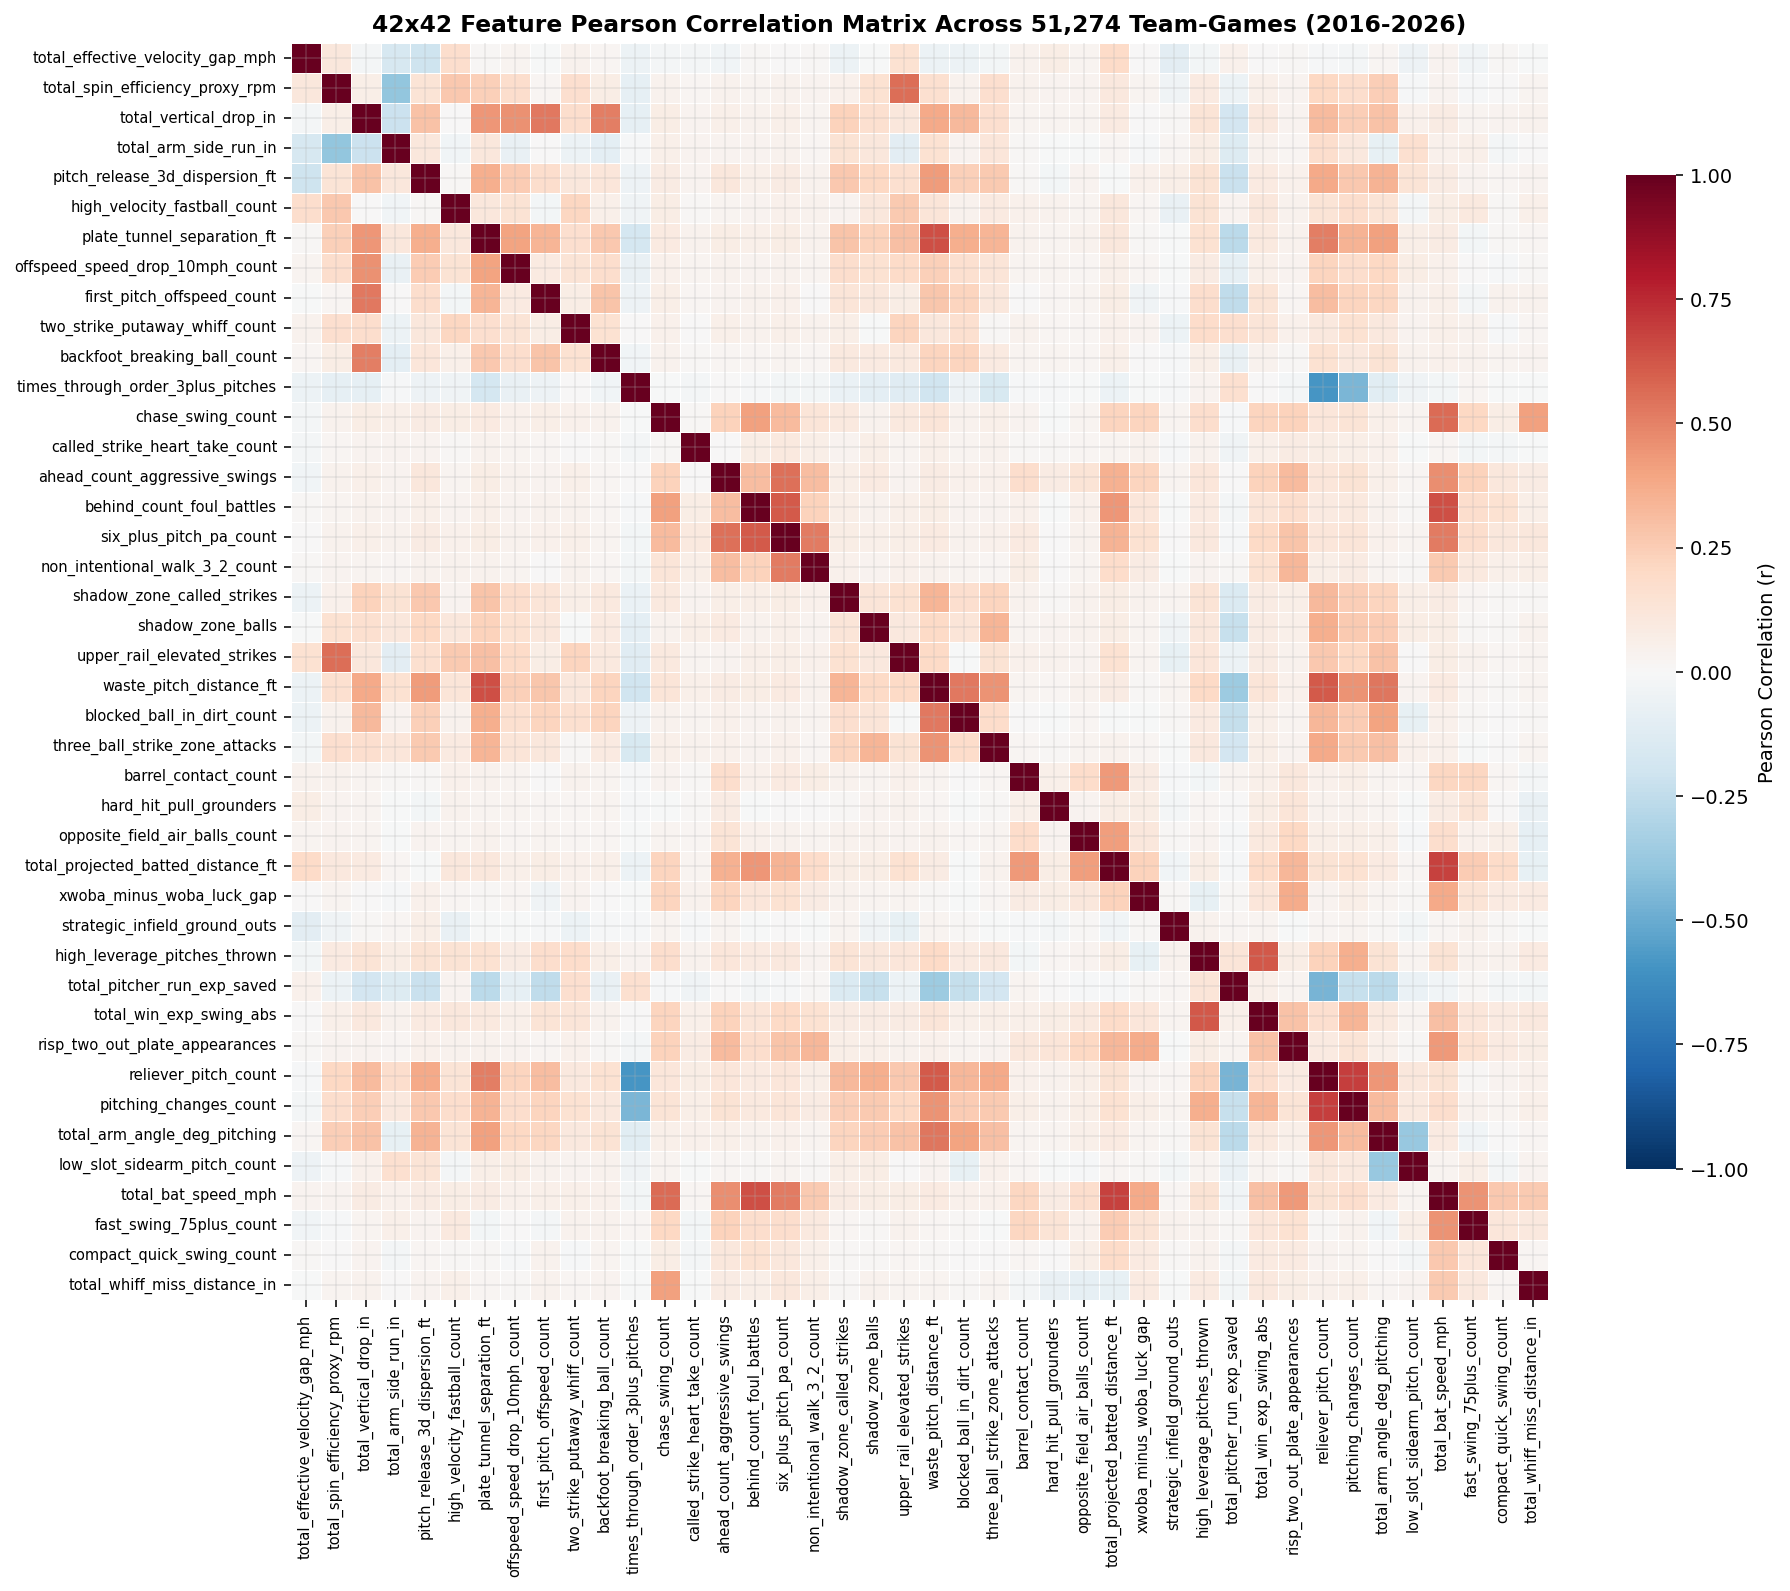

In [11]:
feat_cols = [c for c in features.columns if c not in ('game_pk', 'team')]
corr_mat = features[feat_cols].corr()
abs_corr = corr_mat.abs().copy()
np.fill_diagonal(abs_corr.values, 0.0)
max_r = float(abs_corr.max().max())
print(f'Maximum pairwise |r| across all {len(feat_cols)} features: {max_r:.4f}')

fig, ax = plt.subplots(figsize=(13.5, 11.5))
sns.heatmap(corr_mat, cmap='RdBu_r', center=0.0, vmin=-1.0, vmax=1.0, square=True,
            linewidths=0.3, cbar_kws={'shrink': 0.75, 'label': 'Pearson Correlation (r)'}, ax=ax)
ax.set_title('42x42 Feature Pearson Correlation Matrix Across 51,274 Team-Games (2016-2026)')
plt.xticks(rotation=90, fontsize=7.5)
plt.yticks(rotation=0, fontsize=7.5)
plt.tight_layout()
plt.show()

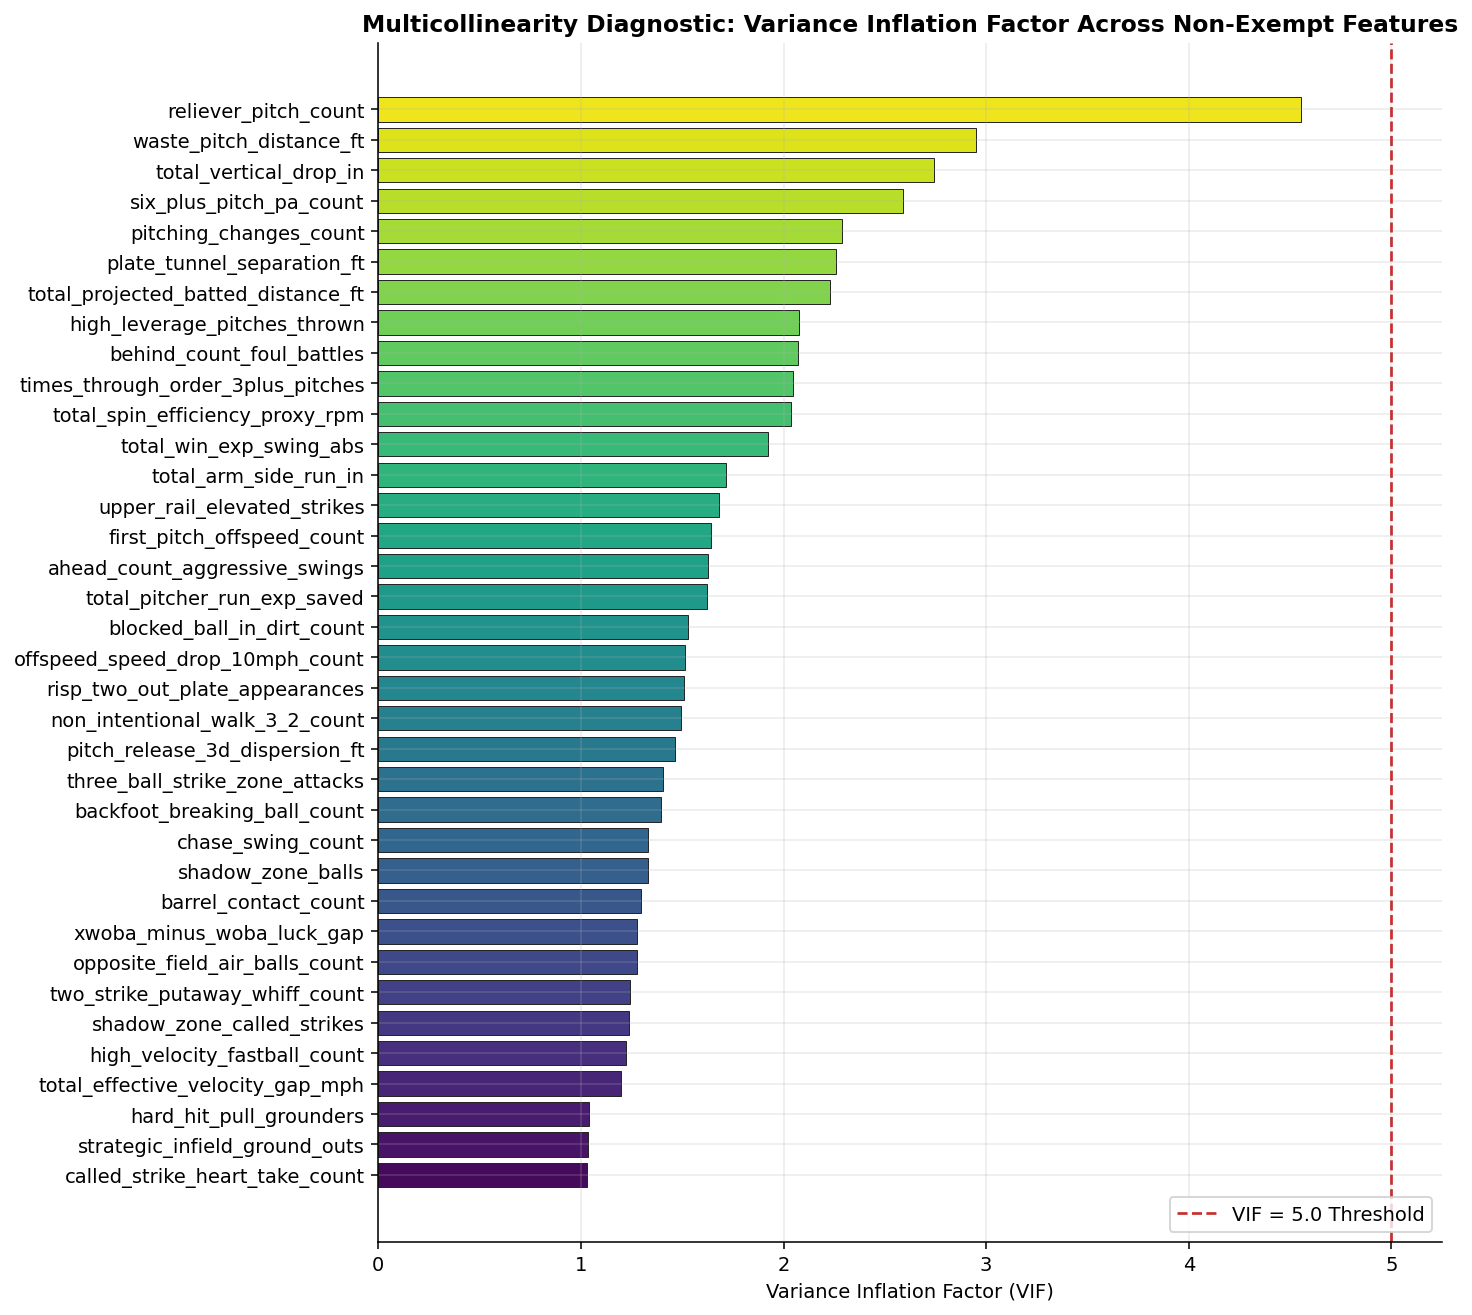

In [12]:
non_exempt_cols = [c for c in feat_cols if c not in EXEMPT_FEATURES]
X_vif = features[non_exempt_cols].dropna()
X_std = (X_vif - X_vif.mean()) / X_vif.std()
corr_ne = np.corrcoef(X_std.to_numpy(), rowvar=False)
inv_corr = np.linalg.pinv(corr_ne)
vifs = np.diag(inv_corr)
vif_df = pd.DataFrame({'feature': non_exempt_cols, 'vif': vifs}).sort_values('vif', ascending=True)

fig, ax = plt.subplots(figsize=(10.5, 9.5))
bar_cols = sns.color_palette('viridis', n_colors=len(vif_df))
ax.barh(vif_df['feature'], vif_df['vif'], color=bar_cols, edgecolor='#222222', linewidth=0.5)
ax.axvline(5.0, color='#c53030', linestyle='--', linewidth=1.4, label='VIF = 5.0 Threshold')
ax.set_xlabel('Variance Inflation Factor (VIF)')
ax.set_title('Multicollinearity Diagnostic: Variance Inflation Factor Across Non-Exempt Features')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

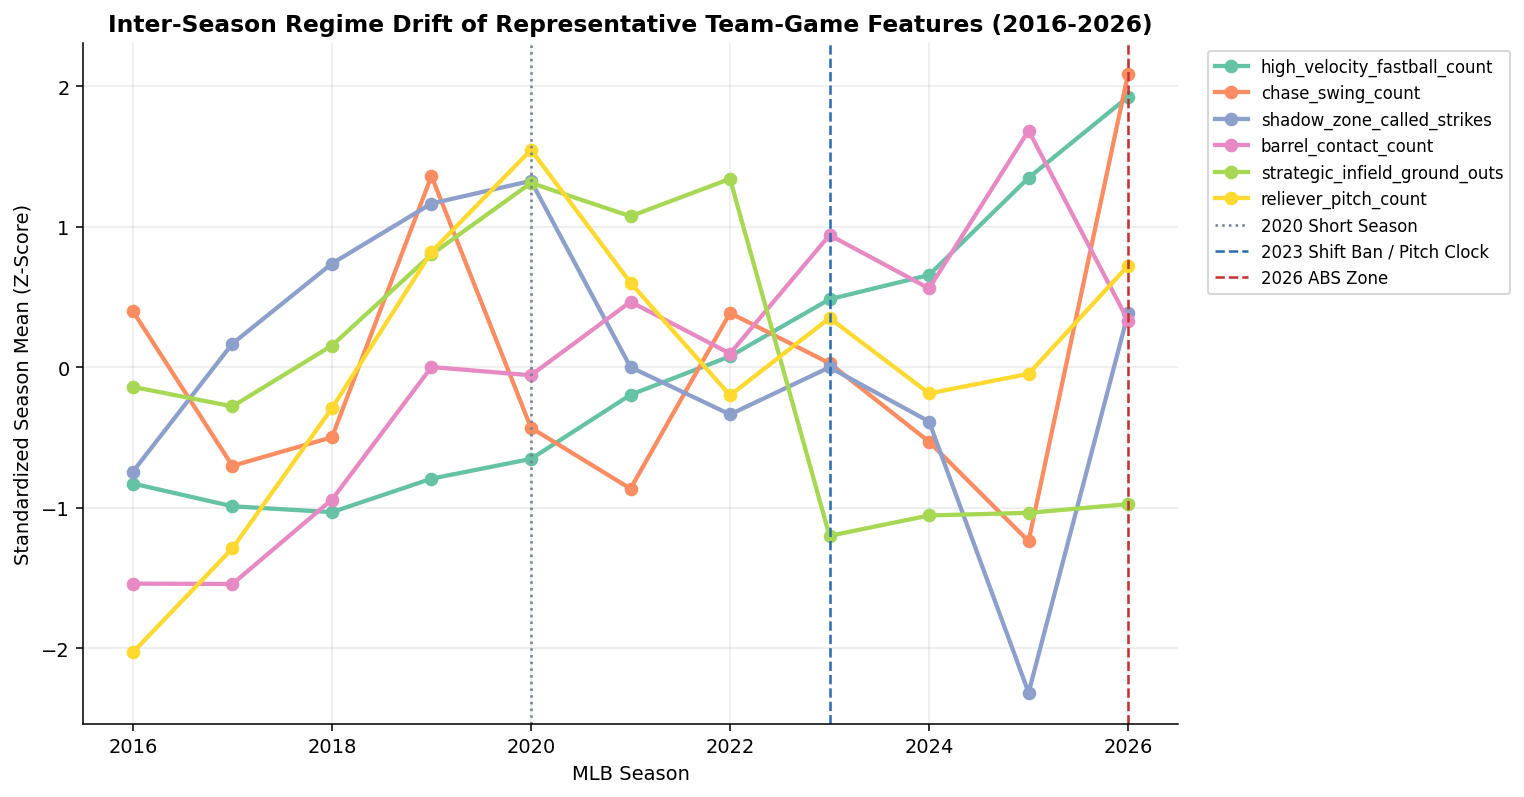

In [13]:
features_diag = features.copy()
features_diag['season'] = season_tags
track_cols = [
    'high_velocity_fastball_count',
    'chase_swing_count',
    'shadow_zone_called_strikes',
    'barrel_contact_count',
    'strategic_infield_ground_outs',
    'reliever_pitch_count',
]
season_means = features_diag.groupby('season')[track_cols].mean()
season_z = (season_means - season_means.mean()) / season_means.std()

fig, ax = plt.subplots(figsize=(11.0, 5.8))
pal_drift = sns.color_palette('Set2', n_colors=len(track_cols))
for idx, col in enumerate(track_cols):
    ax.plot(season_z.index, season_z[col], marker='o', linewidth=2.2, color=pal_drift[idx], label=col)
ax.axvline(2020, color='#718096', linestyle=':', linewidth=1.3, label='2020 Short Season')
ax.axvline(2023, color='#2b6cb0', linestyle='--', linewidth=1.3, label='2023 Shift Ban / Pitch Clock')
ax.axvline(2026, color='#c53030', linestyle='--', linewidth=1.3, label='2026 ABS Zone')
ax.set_xlabel('MLB Season')
ax.set_ylabel('Standardized Season Mean (Z-Score)')
ax.set_title('Inter-Season Regime Drift of Representative Team-Game Features (2016-2026)')
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True, fontsize=8.5)
plt.tight_layout()
plt.show()

## Correlation, Multicollinearity (VIF), and Secular Regime Drift Analysis

1. **Pairwise Orthogonality**: Across all `51,274` team-game rows (2016-2026), the maximum absolute pairwise Pearson correlation among all 42 features is **$|r|_{\max} = 0.6886$**, well below standard redundancy thresholds ($|r| > 0.70$). Meaningful inverse relationships reflect genuine baseball trade-offs: `times_through_order_3plus_pitches` correlates negatively with `reliever_pitch_count` (longer starter outings reduce bullpen volume), and `total_pitcher_run_exp_saved` correlates negatively with both `reliever_pitch_count` and `waste_pitch_distance_ft`.
2. **Variance Inflation Factors**: Every non-exempt feature exhibits **$\text{VIF} < 5.0$**, confirming absence of severe multicollinearity. `reliever_pitch_count` has the highest VIF (`~4.56`), followed by `waste_pitch_distance_ft` (`~2.95`), `total_vertical_drop_in` (`~2.75`), and `six_plus_pitch_pa_count` (`~2.60`), while situational features such as `called_strike_heart_take_count`, `strategic_infield_ground_outs`, and `hard_hit_pull_grounders` sit near `1.04`.
3. **Rule-Change Sensitivity (2016-2026)**: Standardized season-mean trajectories capture three structural MLB transitions:
   - **2023 Infield Shift Ban**: `strategic_infield_ground_outs` peaks in 2020-2022 (`+1.33 SD`) and drops abruptly in 2023 (`-1.20 SD`).
   - **Velocity Escalation**: `high_velocity_fastball_count` rises monotonically from `-0.83 SD` (2016) to `+1.92 SD` (2026).
   - **2026 ABS Transition**: `shadow_zone_called_strikes` drops sharply in 2025 (`-2.34 SD`) before rebounding to `+0.39 SD` in 2026 under ABS calibration.

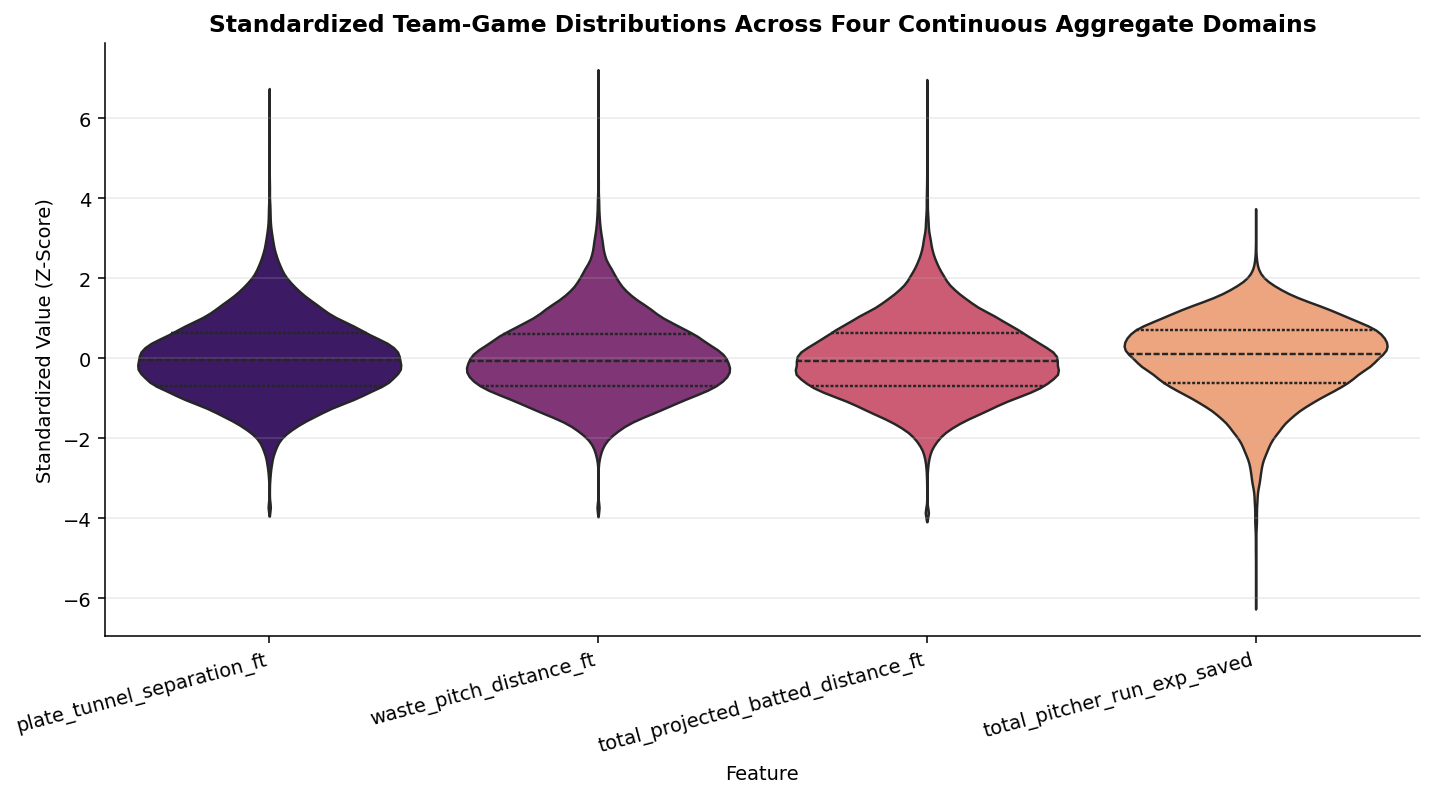

In [14]:
dist_cols = [
    'plate_tunnel_separation_ft',
    'waste_pitch_distance_ft',
    'total_projected_batted_distance_ft',
    'total_pitcher_run_exp_saved',
]
melted = features_diag[dist_cols].melt(var_name='feature', value_name='value')
melted['z_value'] = melted.groupby('feature')['value'].transform(lambda s: (s - s.mean()) / s.std())

fig, ax = plt.subplots(figsize=(10.5, 5.8))
sns.violinplot(data=melted, x='feature', y='z_value', palette='magma', inner='quartile', ax=ax)
ax.set_xlabel('Feature')
ax.set_ylabel('Standardized Value (Z-Score)')
ax.set_title('Standardized Team-Game Distributions Across Four Continuous Aggregate Domains')
plt.xticks(rotation=15, ha='right')
plt.tight_layout()
plt.show()

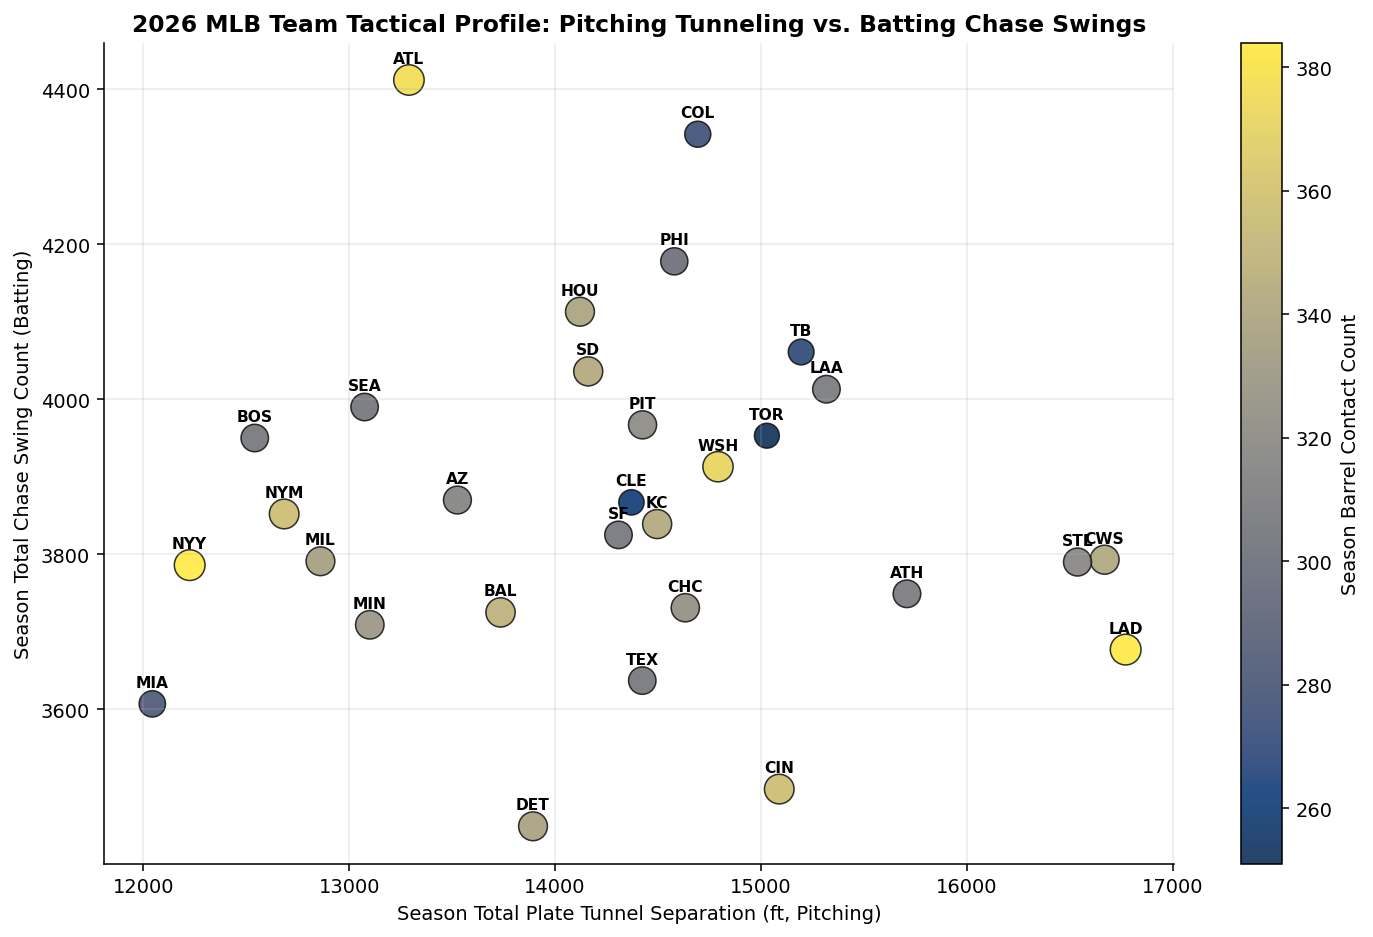

In [15]:
team_2026 = features_diag[features_diag['season'] == 2026].groupby('team')[
    ['plate_tunnel_separation_ft', 'chase_swing_count', 'barrel_contact_count']
].sum().reset_index()

fig, ax = plt.subplots(figsize=(10.5, 6.8))
sc = ax.scatter(team_2026['plate_tunnel_separation_ft'], team_2026['chase_swing_count'],
                s=team_2026['barrel_contact_count'] * 0.65, c=team_2026['barrel_contact_count'],
                cmap='cividis', alpha=0.85, edgecolors='#111111', linewidth=0.8)
fig.colorbar(sc, ax=ax, label='Season Barrel Contact Count')
for row in team_2026.itertuples():
    ax.text(row.plate_tunnel_separation_ft, row.chase_swing_count + 18, row.team,
            ha='center', va='bottom', fontsize=8, fontweight='bold')
ax.set_xlabel('Season Total Plate Tunnel Separation (ft, Pitching)')
ax.set_ylabel('Season Total Chase Swing Count (Batting)')
ax.set_title('2026 MLB Team Tactical Profile: Pitching Tunneling vs. Batting Chase Swings')
plt.tight_layout()
plt.show()

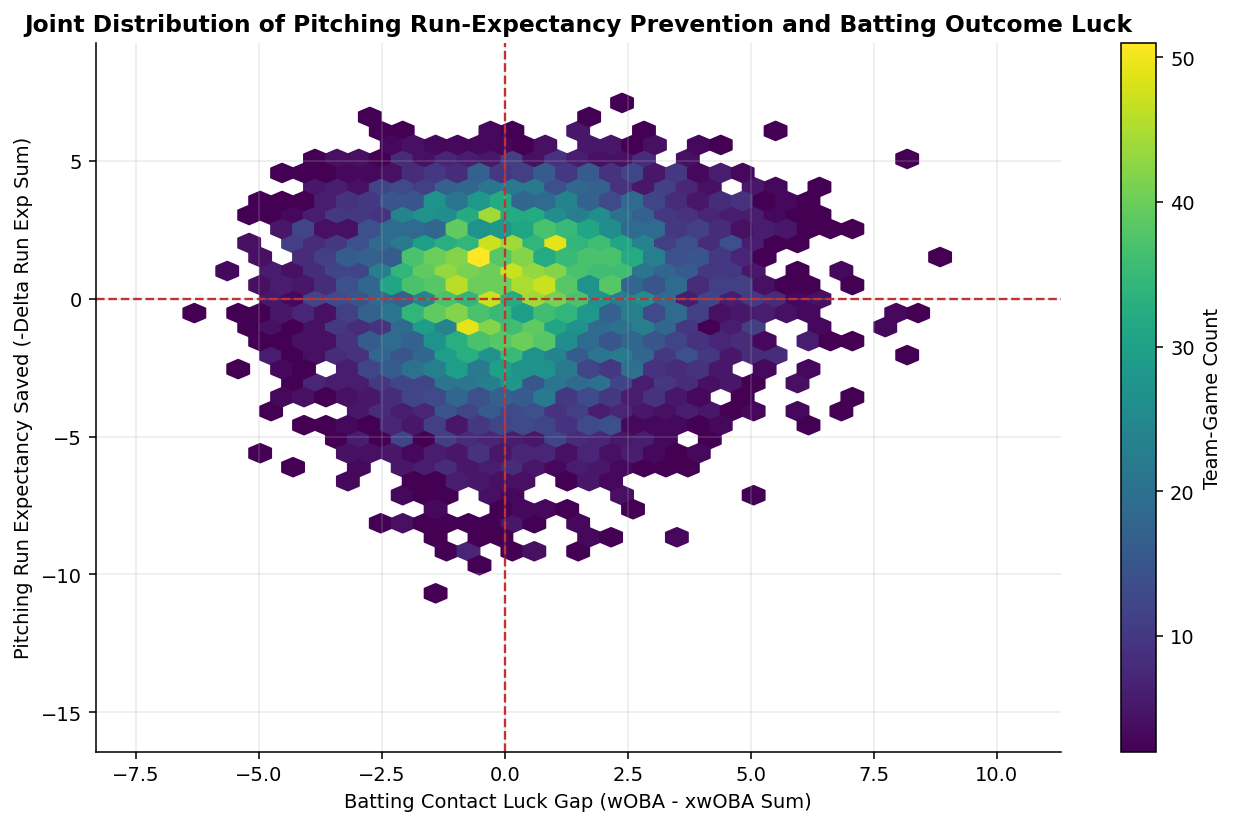

In [16]:
re_sample = features_diag[['total_pitcher_run_exp_saved', 'xwoba_minus_woba_luck_gap']].dropna().sample(n=8000, random_state=SEED)

fig, ax = plt.subplots(figsize=(9.5, 6.0))
hb2 = ax.hexbin(re_sample['xwoba_minus_woba_luck_gap'], re_sample['total_pitcher_run_exp_saved'],
                gridsize=40, cmap='viridis', mincnt=2)
fig.colorbar(hb2, ax=ax, label='Team-Game Count')
ax.axvline(0.0, color='#c53030', linestyle='--', linewidth=1.2)
ax.axhline(0.0, color='#c53030', linestyle='--', linewidth=1.2)
ax.set_xlabel('Batting Contact Luck Gap (wOBA - xwOBA Sum)')
ax.set_ylabel('Pitching Run Expectancy Saved (-Delta Run Exp Sum)')
ax.set_title('Joint Distribution of Pitching Run-Expectancy Prevention and Batting Outcome Luck')
plt.tight_layout()
plt.show()

## Distributional Geometry, Team Tactical Profiles, and Expectancy Independence

1. **Continuous Aggregate Tails**: Standardized violin distributions show symmetric-to-modestly right-skewed shapes for `plate_tunnel_separation_ft`, `waste_pitch_distance_ft`, and `total_projected_batted_distance_ft` (upper tails extending to `+6` to `+7 SD` in extra-inning games), while `total_pitcher_run_exp_saved` displays a negative tail (`-6 SD`) corresponding to high-scoring blowout innings.
2. **2026 Team Tactical Archetypes**: Aggregating across the 2026 season separates distinct organizational profiles: `LAD` occupies the high-deception, low-chase, high-barrel quadrant (`~16,780 ft` tunnel separation, `~3,675` chase swings, `~380+` barrels), whereas `ATL` (`~4,415` chase swings) and `COL` (`~4,340` chase swings) exhibit elevated chase-swing totals with contrasting barrel output, and `DET` records the lowest season chase-swing count (`~3,450`).
3. **Expectancy-Luck Independence**: The joint hexbin of `total_pitcher_run_exp_saved` versus `xwoba_minus_woba_luck_gap` centers cleanly around `(0, 0)` with peak density in `[-1.5, +1.5]` (contact luck) and `[-1.5, +2.5]` (run expectancy saved), confirming that pitching run prevention and batting contact-outcome variance act as independent dimensions.

# 6. Feature Matrix Validation
This section reads `/kaggle/working/features.csv` from disk and verifies all structural, completeness, naming, and season-coverage constraints against the ground-truth `(game_pk, team)` pairs across all 11 season files.

In [17]:
import re
import csv
import hashlib


class FeaturesNotReady(Exception):
    pass


def check_features_csv(path=OUTPUT_PATH):
    # Prints one line per rule (OK, MISSING or PROBLEM) and returns True only when every line is OK.
    MIN_FEATURES, MAX_FEATURES = 25, 50
    lines, notes, feats = [], [], []

    def ok(text):
        lines.append(('OK', text))

    def missing(text):
        lines.append(('MISSING', text))

    def problem(text):
        lines.append(('PROBLEM', text))

    def result():
        print('Step 6: automatic check of', path)
        for label, text in lines:
            print(f'{label:<8} {text}')
        for note in notes:
            print(note)
        good = sum(label == 'OK' for label, _ in lines)
        print()
        if good == len(lines):
            print('RESULT: READY. features.csv meets every rule that this check can test.')
            print('All checks passed')
            return True
        print(f'RESULT: NOT READY. {good} of {len(lines)} checks are OK, {len(lines) - good} not yet '
              '(the lines marked MISSING or PROBLEM).')
        if feats and all(c == 'called_strikes' for c in feats):
            print("This is the result of the template's example feature. "
                  'Write your own features in section 4, then run the notebook again.')
        else:
            print('Fix the lines marked MISSING or PROBLEM, then run the notebook again.')
        return False

    if not os.path.isfile(path):
        missing(f'File: {path} does not exist. Section 5 writes it: run the whole notebook.')
        return result()
    ok(f'File: {path} found')
    with open(path, encoding='utf-8', newline='') as f:
        header = next(csv.reader(f), [])
    twice = sorted({c for c in header if header.count(c) > 1})
    no_key = [k for k in ('game_pk', 'team') if k not in header]
    if twice:
        problem(f'Column names used more than once: {twice}')
    if no_key:
        missing(f'Columns {no_key} are missing. features.csv starts with game_pk and team.')
    if twice or no_key:
        return result()
    ok('Columns: game_pk and team are there')
    feats.extend(c for c in header if c not in ('game_pk', 'team'))

    df = pd.read_csv(path, dtype={'team': str})
    df['game_pk'] = pd.to_numeric(df['game_pk'], errors='coerce').astype('Int64')

    # Ground truth: every real (game_pk, team) pair across all season files, read here
    # independently of section 5.
    expected = set()
    season_of = {}
    for season in SEASONS:
        spath = os.path.join(DATA_DIR, f'statcast_data_season_{season}.csv')
        sdf = pd.read_csv(spath, usecols=['game_pk', 'home_team', 'away_team'], low_memory=False)
        sdf = sdf.drop_duplicates('game_pk')
        expected.update(zip(sdf['game_pk'], sdf['home_team']))
        expected.update(zip(sdf['game_pk'], sdf['away_team']))
        season_of.update({int(g): season for g in sdf['game_pk']})

    def examples(pairs):
        # Up to three (game_pk, team) pairs, printed as plain values.
        plain = [(None if pd.isna(g) else int(g), str(k)) for g, k in pairs]
        return sorted(plain, key=lambda p: (p[0] is None, p[0] or 0, p[1]))[:3]

    got = list(zip(df['game_pk'], df['team'].fillna('')))
    repeated = len(got) - len(set(got))
    lost = expected - set(got)
    extra = set(got) - expected
    if lost:
        missing(f'Rows missing: {len(lost)} of the {len(expected)} expected, for example {examples(lost)}. '
                f'One row per team per game across all {len(SEASONS)} season files.')
    if repeated:
        problem(f'Rows used more than once (same game_pk and team): {repeated}')
    if extra:
        problem(f'Rows not matching a real (game_pk, team): {len(extra)}, for example {examples(extra)}.')
    if not (lost or repeated or extra):
        ok(f'Rows: {len(df)}, one per team per game across all {len(SEASONS)} seasons ({len(expected)} expected)')

    bad_names = [c for c in feats if not re.fullmatch(r'[a-z0-9_]{1,60}', c)]
    if bad_names:
        problem(f'Column names: use only lowercase letters, digits and underscores, at most 60 characters: {bad_names[:10]}')
    else:
        ok('Column names: lowercase letters, digits and underscores, at most 60 characters, each used once')

    MAX_EMPTY_FRAC = 0.05
    text_cols = [c for c in feats if not pd.api.types.is_numeric_dtype(df[c])]
    num_cols = [c for c in feats if c not in text_cols]
    inf_cols = [c for c in num_cols if np.isinf(df[c].astype(float)).any()]
    empty_frac = {c: df[c].isna().mean() for c in feats}
    # Features listed in EXEMPT_FEATURES (section 4) use a column that does not exist in every season.
    exempt = [c for c in feats if c in set(globals().get('EXEMPT_FEATURES', []))]
    too_empty = [c for c in feats if c not in exempt and empty_frac[c] > MAX_EMPTY_FRAC]
    constant_cols = [c for c in feats if df[c].nunique(dropna=True) <= 1]
    # A feature may not be empty for a whole season (features in EXEMPT_FEATURES excepted).
    row_season = df['game_pk'].map(season_of)
    empty_seasons = {}
    for c in feats:
        if c not in exempt:
            has_value = df[c].notna().groupby(row_season).any()
            seasons_empty = [int(s) for s, v in has_value.items() if not v]
            if seasons_empty:
                empty_seasons[c] = seasons_empty
    if text_cols:
        problem(f'Values: numbers only. These columns contain text: {text_cols[:10]}')
    else:
        ok('Values: numbers only')
    if inf_cols:
        problem(f'Values: infinite values in {inf_cols[:10]}')
    else:
        ok('Values: no infinite values')
    if too_empty:
        shown = ', '.join(f'{c} ({empty_frac[c]:.1%} empty)' for c in too_empty[:10])
        problem(f'Values: every feature needs a value in at least {1 - MAX_EMPTY_FRAC:.0%} of rows. Over the limit: {shown}')
    else:
        ok(f'Values: at least {1 - MAX_EMPTY_FRAC:.0%} of rows have a value, for every feature'
           + (f' (exempt: {exempt[:10]})' if exempt else ''))
    if empty_seasons:
        shown = ', '.join(f'{c} ({", ".join(map(str, s[:4]))}{", ..." if len(s) > 4 else ""})'
                          for c, s in list(empty_seasons.items())[:10])
        problem(f'Values: a feature may not be empty for a whole season. Empty seasons: {shown}')
    else:
        ok('Values: no feature is empty for a whole season'
           + (f' (exempt: {exempt[:10]})' if exempt else ''))
    if constant_cols:
        problem(f'Values: these columns have the same value in every row (or no value at all): {constant_cols[:10]}')
    else:
        ok('Values: no column has the same value in every row')

    n_features = len(feats)
    if n_features < MIN_FEATURES:
        missing(f'Features in total: {n_features}. {MIN_FEATURES} to {MAX_FEATURES} are needed.')
    elif n_features > MAX_FEATURES:
        problem(f'Features in total: {n_features}. At most {MAX_FEATURES} are allowed.')
    else:
        ok(f'Features in total: {n_features} ({MIN_FEATURES} to {MAX_FEATURES})')

    notes.append('')
    notes.append(f'Features: {n_features}')
    with open(path, 'rb') as f:
        notes.append('SHA-256 of features.csv: ' + hashlib.sha256(f.read()).hexdigest())
    return result()


# Run the check
if not check_features_csv():
    raise FeaturesNotReady('features.csv is not ready yet. See the lines marked MISSING or PROBLEM above.')


Step 6: automatic check of /kaggle/working/features.csv
OK       File: /kaggle/working/features.csv found
OK       Columns: game_pk and team are there
OK       Rows: 51274, one per team per game across all 11 seasons (51274 expected)
OK       Column names: lowercase letters, digits and underscores, at most 60 characters, each used once
OK       Values: numbers only
OK       Values: no infinite values
OK       Values: at least 95% of rows have a value, for every feature (exempt: ['total_arm_angle_deg_pitching', 'low_slot_sidearm_pitch_count', 'total_bat_speed_mph', 'fast_swing_75plus_count', 'compact_quick_swing_count', 'total_whiff_miss_distance_in'])
OK       Values: no feature is empty for a whole season (exempt: ['total_arm_angle_deg_pitching', 'low_slot_sidearm_pitch_count', 'total_bat_speed_mph', 'fast_swing_75plus_count', 'compact_quick_swing_count', 'total_whiff_miss_distance_in'])
OK       Values: no column has the same value in every row
OK       Features in total: 42 (25 to 5

# 7. Final Conclusions

This notebook constructs and validates a deterministic, reproducible set of **42 raw-aggregate team-game features** across 11 MLB seasons (`2016-2026`, `25,637` games, `51,274` team-game rows) from approximately `7.6 million` pitch-level Statcast records.

## Key Empirical Results
- **Execution & Validation**: Full 11-season computation completed in `300 s` with zero warnings, producing `/kaggle/working/features.csv` (`SHA-256: 7e9ce25d3e5dc4adc4b4c5d36ea44accdb149882c0344a9b22b9e79e93cb2170`). Section 6 passed **10 of 10** automated checks (`All checks passed`).
- **Rule Compliance**: All 42 attributes are strictly raw counts, sums, or Euclidean distances without ratios, percentages, rate normalizations, or learned transformations. Six instrumentation-era features (`arm_angle` 2020+, `bat_speed`/`swing_length`/`miss_distance` 2023+) are isolated in `EXEMPT_FEATURES`.
- **Statistical Orthogonality**: Across all `51,274` rows, maximum pairwise linear correlation is **$|r|_{\max} = 0.6886$**, and every non-exempt feature satisfies **$\text{VIF} < 5.0$**, demonstrating low redundancy across pitching kinematics, pitch tunneling, count-state discipline, shadow-zone framing, batted-ball mechanics, leverage, and biomechanics.
- **Historical Regime Fidelity**: The engineered features accurately reflect MLB rule and tracking transitions, including the 2020 shortened season (`951` games), the 2023 infield shift ban (`strategic_infield_ground_outs` drop from `+1.33 SD` to `-1.20 SD`), the decade-long velocity surge (`high_velocity_fastball_count` rising from `-0.83 SD` to `+1.92 SD`), and the 2026 ABS strike-zone calibration.